# GEM EDUCA — Sesión N.° 03
## DATOS, FEATURES Y REPRODUCIBILIDAD

> **Propósito del laboratorio:** transformar datos relacionales crudos en un flujo de *Machine Learning* (ML) reproducible, modular y auditable. No se trata solo de “entrenar un modelo”: se trata de poder explicar **de dónde viene cada variable, cuándo se calculó, con qué datos y cómo repetir exactamente el resultado**.


---

### Al finalizar la sesión podrás

1. Distinguir **dato crudo**, **variable**, **feature**, **target**, **metadato** y **artefacto**.
2. Modelar relaciones **PK/FK** entre tablas.
3. Detectar problemas de calidad, duplicados, faltantes e integridad referencial.
4. Evitar **data leakage** y contaminación entre entrenamiento y prueba.
5. Construir *features* numéricas, categóricas, temporales, RFM, ratios e interacciones.
6. Crear pipelines con `scikit-learn`.
7. Comparar modelos con métricas adecuadas para clasificación.
8. Guardar modelo, configuración, hashes, resultados y versiones.
9. Medir una forma básica de *data drift* mediante **PSI**.
10. Organizar un proyecto con `src/`, `config/`, `data/`, `models/` y `artifacts/`.

# 1. Mapa conceptual de la sesión

```text
PROBLEMA
│
├── 1) DATOS
│   ├── Fuente
│   ├── Granularidad
│   ├── PK / FK
│   ├── Tipos
│   ├── Calidad
│   └── Momento temporal
│
├── 2) FEATURES
│   ├── Numéricas
│   │   ├── escalas
│   │   ├── logaritmos
│   │   ├── ratios
│   │   └── interacciones
│   ├── Categóricas
│   │   ├── imputación
│   │   └── One-Hot Encoding
│   ├── Temporales
│   │   ├── recencia
│   │   ├── ventanas
│   │   ├── tendencia
│   │   └── codificación cíclica
│   └── Relacionales
│       ├── agregaciones 1:N
│       └── RFM
│
├── 3) VALIDACIÓN
│   ├── Train / Test
│   ├── Cross-Validation
│   ├── métricas
│   └── leakage checks
│
└── 4) REPRODUCIBILIDAD
    ├── seed
    ├── configuración
    ├── versiones
    ├── hash de datos
    ├── pipeline
    ├── modelo serializado
    └── registro de experimentos
```

### Árbol de decisión para crear una feature

```text
¿La variable existiría en el momento real de predicción?
├── NO → NO usarla: leakage.
└── SÍ
    ├── ¿Es numérica?
    │   ├── ¿Muy asimétrica? → log1p / transformación robusta.
    │   ├── ¿Escala muy distinta? → escalado.
    │   └── ¿Tiene significado relativo? → ratio / interacción.
    ├── ¿Es categórica?
    │   ├── Pocas categorías → One-Hot Encoding.
    │   └── Muchas categorías → agrupar raras / hashing / encoding validado.
    └── ¿Es temporal?
        ├── Recencia → días desde último evento.
        ├── Frecuencia → conteos por ventana.
        ├── Magnitud → suma / media / máximo.
        └── Estacionalidad → seno y coseno.
```

### Cómo leer el mapa

El flujo no es lineal en la práctica: se vuelve atrás muchas veces. Si una métrica empeora, no se debe saltar inmediatamente a un modelo más complejo. Primero se revisan **datos, definición temporal, target, features y split**.

Una pregunta útil en cada etapa es: **“¿Qué información tendría realmente disponible el sistema en el instante en que debe tomar la decisión?”**. Esa pregunta conecta calidad de datos, ingeniería de características y prevención de *leakage*.

# 2. Glosario mínimo de siglas y conceptos

- **ML — Machine Learning:** aprendizaje automático.
- **EDA — Exploratory Data Analysis:** análisis exploratorio de datos.
- **ETL — Extract, Transform, Load:** extraer, transformar y cargar.
- **ELT — Extract, Load, Transform:** extraer, cargar y luego transformar.
- **PK — Primary Key:** clave primaria; identifica unívocamente una fila.
- **FK — Foreign Key:** clave foránea; enlaza una fila con otra tabla.
- **FE — Feature Engineering:** ingeniería de características.
- **RFM — Recency, Frequency, Monetary:** recencia, frecuencia y valor monetario.
- **OHE — One-Hot Encoding:** transforma una categoría en columnas binarias.
- **CV — Cross-Validation:** validación cruzada.
- **ROC-AUC:** área bajo la curva ROC; mide capacidad de ranking entre clases.
- **PR-AUC:** área bajo la curva precisión–recobrado; útil cuando la clase positiva es poco frecuente.
- **F1:** media armónica entre precisión y recobrado.
- **PSI — Population Stability Index:** índice de estabilidad poblacional para comparar distribuciones.
- **SHA-256:** función hash criptográfica; permite verificar si un archivo cambió.
- **Seed:** semilla pseudoaleatoria para repetir resultados.
- **Pipeline:** secuencia encapsulada de transformaciones y modelo.
- **Data leakage:** uso accidental de información que en producción no existiría al momento de predecir.
- **Snapshot:** “fotografía” temporal del sistema en una fecha definida.
- **Artefacto:** archivo generado por el experimento, por ejemplo modelo, métricas, configuración o manifiesto.

### Diferencias que conviene no mezclar

- **Dato crudo:** observación recibida desde una fuente, todavía sin reinterpretar.
- **Variable:** campo medido o registrado, por ejemplo `age`.
- **Feature:** representación preparada para el modelo; puede coincidir con una variable original o ser derivada.
- **Target:** resultado que queremos predecir o explicar.
- **Parámetro:** valor aprendido por el modelo, por ejemplo un coeficiente.
- **Hiperparámetro:** configuración elegida antes o durante el entrenamiento, como `max_depth`.
- **Artefacto:** salida persistente del proceso: modelo, métricas, configuración, hash o gráfico.

# 3. Arquitectura modular que construiremos

```text
gem_s03/
├── config/
│   └── config.yaml
├── data/
│   ├── raw/
│   ├── interim/
│   └── processed/
├── models/
├── artifacts/
├── src/
│   ├── data.py
│   ├── features.py
│   ├── modeling.py
│   ├── monitoring.py
│   └── repro.py
└── notebook.ipynb
```

**Separar responsabilidades** permite probar una parte sin reescribir todas las demás. El notebook funciona como capa didáctica y de orquestación; la lógica reutilizable vive en `src/`.

### Responsabilidad de cada módulo

```text
data.py
└── crea o adquiere datos; no entrena modelos

features.py
└── transforma tablas crudas en una matriz analítica

modeling.py
├── define preprocesamiento
├── define estimadores
└── evalúa y registra métricas

monitoring.py
└── compara distribuciones entre referencia y datos nuevos

repro.py
├── fija semillas
├── calcula hashes
└── registra el entorno
```

Esta separación reduce **acoplamiento**: cambiar el modelo no obliga a reescribir la adquisición de datos, y cambiar la fuente no debería obligar a reescribir las métricas.

In [ ]:
# `-q` reduce el ruido de instalación en clase; no cambia qué paquetes se instalan.
# `pyyaml` leerá la configuración YAML y `joblib` serializará el pipeline entrenado.

# 4. Preparación del entorno
# Colab suele traer NumPy, pandas, scikit-learn y matplotlib.
# Esta celda instala/actualiza únicamente utilidades pequeñas que usaremos.
!pip -q install pyyaml joblib

In [ ]:
# Separaremos imports por responsabilidad: rutas/sistema, datos/gráficos y validación de ML.
# La semilla fija las operaciones pseudoaleatorias que sí respetan NumPy/Python;
# no convierte automáticamente en determinista cualquier librería o hardware.

# 5. Imports y configuración visual
from pathlib import Path
import os, sys, json, random, hashlib, platform, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

Python: 3.13.16
NumPy: 2.1.3
pandas: 2.2.3


# 6. Google Drive: persistencia opcional

Colab borra `/content` cuando termina la sesión. **Google Drive** permite conservar datos, modelos y resultados.

Usaremos dos modos:

```text
Modo A — rápido para clase
/content/gem_s03

Modo B — persistente
/content/drive/MyDrive/GEM_EDUCA/gem_s03
```

La opción `USE_DRIVE` permite cambiar entre ambos sin reescribir rutas.

### ¿Qué cambia al montar Drive?

`/content` es almacenamiento **efímero**: desaparece al reiniciar el entorno.  
`/content/drive/MyDrive/...` es almacenamiento **persistente** en la cuenta autorizada.

Para clase conviene comenzar con `USE_DRIVE = False`; cuando el flujo funciona, se cambia a `True` para conservar resultados. Así separamos errores del código de problemas de permisos o montaje.

In [ ]:
# `USE_DRIVE=False` mantiene el laboratorio aislado de permisos de Google.
# Si se activa, ROOT apunta a Drive; si no, apunta al disco efímero de Colab.
# Todo el resto del notebook usa ROOT, por lo que no hay que reescribir rutas.

# Ejecuta esta celda si deseas guardar todo de forma persistente en Google Drive.
USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/GEM_EDUCA/gem_s03")
else:
    ROOT = Path("/content/gem_s03")

for folder in [
    "config", "data/raw", "data/interim", "data/processed",
    "models", "artifacts", "src"
]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("ROOT =", ROOT)

Mounted at /content/drive
ROOT = /content/drive/MyDrive/GEM_EDUCA/gem_s03


# 7. Crear módulos desde el propio notebook

Esta técnica es útil en docencia: el estudiante ve la lógica y, al mismo tiempo, aprende a **sacar funciones del notebook** para crear un proyecto mantenible.

> En producción, lo habitual es mantener estos módulos en un repositorio Git y que el notebook solo los importe.

### Por qué sacar funciones del notebook

Un notebook es excelente para narrar un análisis, pero no es el mejor lugar para repetir lógica. Cuando una transformación se convierte en una función de `src/`, ganamos:

1. **reutilización:** la misma regla se usa en entrenamiento e inferencia;
2. **testabilidad:** podemos verificar la función aislada;
3. **trazabilidad:** sabemos exactamente dónde vive la regla;
4. **menor riesgo de divergencia:** evitamos tener dos copias ligeramente distintas del mismo código.

In [ ]:
# `MODULES` relaciona nombre de archivo -> código fuente.
# El objetivo es mostrar que la lógica reusable puede vivir fuera del notebook.
# Después escribimos cada cadena en ROOT/src y añadimos esa carpeta a `sys.path`
# para importarla como cualquier módulo Python.

# Escribimos los módulos del proyecto.
MODULES = {
    "data.py": 'from __future__ import annotations\nimport numpy as np\nimport pandas as pd\n\ndef make_relational_demo(\n    n_customers: int = 2500,\n    seed: int = 42,\n    snapshot_date: str = "2026-09-01"\n):\n    """\n    Genera un sistema relacional sintético con:\n      1) customers: una fila por cliente.\n      2) transactions: muchas transacciones por cliente.\n      3) support: cero o varios tickets por cliente.\n      4) target: churn futuro definido a partir de actividad posterior al snapshot.\n\n    La idea docente importante es que las FEATURES se construyen solo con información\n    disponible ANTES del snapshot, mientras que el TARGET usa el futuro.\n    """\n    rng = np.random.default_rng(seed)\n    snapshot = pd.Timestamp(snapshot_date)\n    customer_ids = np.arange(100_000, 100_000 + n_customers)\n\n    region = rng.choice(["Costa", "Sierra", "Selva", "Exterior"], n_customers, p=[.36, .38, .20, .06])\n    plan = rng.choice(["Basic", "Plus", "Pro"], n_customers, p=[.48, .34, .18])\n    channel = rng.choice(["Organic", "Ads", "Referral", "Partner"], n_customers, p=[.34, .31, .22, .13])\n    age = np.clip(rng.normal(36, 11, n_customers).round(), 18, 75)\n    income = np.exp(rng.normal(np.log(3200), .55, n_customers))\n    signup_days_ago = rng.integers(45, 1200, n_customers)\n    signup_date = snapshot - pd.to_timedelta(signup_days_ago, unit="D")\n\n    # Propensión latente: no se entrega al modelo; solo ayuda a generar datos plausibles.\n    plan_effect = pd.Series(plan).map({"Basic": -0.35, "Plus": 0.10, "Pro": 0.42}).to_numpy()\n    channel_effect = pd.Series(channel).map({"Organic": 0.15, "Ads": -0.12, "Referral": 0.28, "Partner": 0.03}).to_numpy()\n    latent_engagement = (\n        rng.normal(0, 0.75, n_customers)\n        + plan_effect\n        + channel_effect\n        + 0.00005 * (income - np.median(income))\n    )\n\n    customers = pd.DataFrame({\n        "customer_id": customer_ids,\n        "signup_date": signup_date,\n        "age": age.astype(float),\n        "income_monthly": income.round(2),\n        "region": region,\n        "plan": plan,\n        "acquisition_channel": channel,\n    })\n\n    # Introducimos faltantes realistas para practicar imputación.\n    for col, frac in [("age", 0.035), ("income_monthly", 0.055)]:\n        idx = rng.choice(n_customers, int(frac*n_customers), replace=False)\n        customers.loc[idx, col] = np.nan\n\n    # -----------------------------\n    # Transacciones históricas\n    # -----------------------------\n    tx_rows = []\n    tx_id = 1\n    for i, cid in enumerate(customer_ids):\n        lam = np.clip(7 + 5*latent_engagement[i], 0.8, 28)\n        n_hist = int(rng.poisson(lam))\n        if n_hist == 0:\n            continue\n\n        recency_bias = np.clip(0.55 + 0.14*latent_engagement[i], 0.18, 0.90)\n        # Mezcla fechas recientes y antiguas.\n        recent = rng.random(n_hist) < recency_bias\n        days_ago = np.where(\n            recent,\n            rng.integers(1, 91, n_hist),\n            rng.integers(91, 366, n_hist)\n        )\n        tx_dates = snapshot - pd.to_timedelta(days_ago, unit="D")\n\n        base_amount = {"Basic": 45, "Plus": 75, "Pro": 125}[plan[i]]\n        amounts = np.maximum(\n            3,\n            rng.lognormal(mean=np.log(base_amount), sigma=.55, size=n_hist)\n        )\n        categories = rng.choice(\n            ["Food", "Home", "Tech", "Services", "Education"],\n            n_hist,\n            p=[.28, .20, .17, .20, .15]\n        )\n        discounts = np.clip(rng.normal(0.08 if channel[i] == "Ads" else 0.04, .05, n_hist), 0, .35)\n        units = np.maximum(1, rng.poisson(1.6, n_hist))\n\n        for d, a, c, disc, u in zip(tx_dates, amounts, categories, discounts, units):\n            tx_rows.append((tx_id, cid, d, float(a), int(u), c, float(disc)))\n            tx_id += 1\n\n    transactions = pd.DataFrame(\n        tx_rows,\n        columns=["transaction_id","customer_id","transaction_date","amount","units","category","discount_pct"]\n    )\n\n    # -----------------------------\n    # Tickets de soporte\n    # -----------------------------\n    support_rows = []\n    ticket_id = 1\n    for i, cid in enumerate(customer_ids):\n        # Menor engagement y plan Basic -> más tickets en promedio.\n        lam = np.clip(1.4 - 0.38*latent_engagement[i] + (plan[i] == "Basic")*.25, .05, 4.5)\n        n_tickets = int(rng.poisson(lam))\n        if n_tickets == 0:\n            continue\n        days_ago = rng.integers(1, 181, n_tickets)\n        dates = snapshot - pd.to_timedelta(days_ago, unit="D")\n        issue = rng.choice(["Billing","Technical","Delivery","Cancellation","Other"], n_tickets,\n                           p=[.24,.30,.18,.12,.16])\n        severity = rng.choice(["Low","Medium","High"], n_tickets, p=[.48,.39,.13])\n        resolution = np.clip(\n            rng.lognormal(mean=np.log(10), sigma=.7, size=n_tickets)\n            * np.where(severity=="High", 1.8, 1.0),\n            0.5, 120\n        )\n        for d, iss, sev, rh in zip(dates, issue, severity, resolution):\n            support_rows.append((ticket_id, cid, d, iss, sev, float(rh)))\n            ticket_id += 1\n\n    support = pd.DataFrame(\n        support_rows,\n        columns=["ticket_id","customer_id","ticket_date","issue_type","severity","resolution_hours"]\n    )\n\n    # -----------------------------\n    # Target futuro: churn en 30 días\n    # -----------------------------\n    # No usamos una columna "churn" preexistente como feature.\n    # La probabilidad depende de señales plausibles que el histórico puede aproximar.\n    hist_counts = transactions.groupby("customer_id").size().reindex(customer_ids, fill_value=0).to_numpy()\n    last_date = transactions.groupby("customer_id")["transaction_date"].max().reindex(customer_ids)\n    recency = (snapshot - last_date).dt.days.fillna(365).to_numpy()\n\n    logit_active = (\n        1.25\n        + 0.75*latent_engagement\n        + 0.045*np.minimum(hist_counts, 30)\n        - 0.018*np.minimum(recency, 180)\n        + 0.18*(plan == "Pro")\n    )\n    p_active = 1 / (1 + np.exp(-logit_active))\n    future_active = rng.binomial(1, np.clip(p_active, .02, .98))\n    target = pd.DataFrame({\n        "customer_id": customer_ids,\n        "churn_30d": (1 - future_active).astype(int)\n    })\n\n    return customers, transactions, support, target',
    "features.py": 'from __future__ import annotations\nimport numpy as np\nimport pandas as pd\n\ndef validate_relations(customers, transactions, support):\n    """Valida PK, FK y reglas mínimas de calidad."""\n    assert customers["customer_id"].is_unique, "customer_id debe ser PK única en customers."\n    if len(transactions):\n        assert transactions["transaction_id"].is_unique, "transaction_id duplicado."\n        assert set(transactions["customer_id"]).issubset(set(customers["customer_id"])), "FK inválida en transactions."\n        assert (transactions["amount"] >= 0).all(), "Existen montos negativos."\n    if len(support):\n        assert support["ticket_id"].is_unique, "ticket_id duplicado."\n        assert set(support["customer_id"]).issubset(set(customers["customer_id"])), "FK inválida en support."\n    return True\n\ndef _safe_div(num, den):\n    den = den.replace(0, np.nan)\n    return num / den\n\ndef build_customer_features(customers, transactions, support, snapshot_date="2026-09-01"):\n    """\n    Construye features SOLO con datos previos al snapshot.\n    Incluye RFM, ventanas temporales, tendencia, soporte, ratios e interacciones.\n    """\n    snapshot = pd.Timestamp(snapshot_date)\n\n    c = customers.copy()\n    c["signup_date"] = pd.to_datetime(c["signup_date"])\n    c["tenure_days"] = (snapshot - c["signup_date"]).dt.days\n    c["signup_month"] = c["signup_date"].dt.month\n    c["signup_month_sin"] = np.sin(2*np.pi*c["signup_month"]/12)\n    c["signup_month_cos"] = np.cos(2*np.pi*c["signup_month"]/12)\n\n    tx = transactions.copy()\n    tx["transaction_date"] = pd.to_datetime(tx["transaction_date"])\n    tx = tx[tx["transaction_date"] < snapshot].copy()\n    tx["days_ago"] = (snapshot - tx["transaction_date"]).dt.days\n    tx["is_weekend"] = tx["transaction_date"].dt.dayofweek.ge(5).astype(int)\n    tx["net_amount"] = tx["amount"] * (1 - tx["discount_pct"])\n\n    # RFM global.\n    agg = tx.groupby("customer_id").agg(\n        txn_count=("transaction_id","count"),\n        monetary_total=("net_amount","sum"),\n        avg_ticket=("net_amount","mean"),\n        spend_std=("net_amount","std"),\n        last_txn_date=("transaction_date","max"),\n        unique_categories=("category","nunique"),\n        avg_discount=("discount_pct","mean"),\n        weekend_share=("is_weekend","mean"),\n        units_total=("units","sum"),\n    ).reset_index()\n    agg["recency_days"] = (snapshot - agg["last_txn_date"]).dt.days\n    agg = agg.drop(columns="last_txn_date")\n\n    # Ventanas 30 y 90 días.\n    def win_features(days):\n        w = tx[tx["days_ago"].between(1, days)]\n        out = w.groupby("customer_id").agg(\n            **{\n                f"txn_count_{days}d": ("transaction_id","count"),\n                f"spend_{days}d": ("net_amount","sum"),\n                f"units_{days}d": ("units","sum"),\n            }\n        ).reset_index()\n        return out\n\n    w30 = win_features(30)\n    w90 = win_features(90)\n\n    # Ventana 31-60 para una feature de tendencia.\n    prev = tx[tx["days_ago"].between(31,60)].groupby("customer_id").agg(\n        spend_prev_30d=("net_amount","sum"),\n        txn_prev_30d=("transaction_id","count")\n    ).reset_index()\n\n    # Soporte.\n    s = support.copy()\n    s["ticket_date"] = pd.to_datetime(s["ticket_date"])\n    s = s[s["ticket_date"] < snapshot].copy()\n    s["days_ago"] = (snapshot - s["ticket_date"]).dt.days\n    s["is_high"] = (s["severity"] == "High").astype(int)\n    s90 = s[s["days_ago"].between(1,90)].groupby("customer_id").agg(\n        tickets_90d=("ticket_id","count"),\n        high_severity_90d=("is_high","sum"),\n        avg_resolution_hours_90d=("resolution_hours","mean"),\n        issue_diversity_90d=("issue_type","nunique")\n    ).reset_index()\n\n    df = c.merge(agg, on="customer_id", how="left") \\\n          .merge(w30, on="customer_id", how="left") \\\n          .merge(w90, on="customer_id", how="left") \\\n          .merge(prev, on="customer_id", how="left") \\\n          .merge(s90, on="customer_id", how="left")\n\n    count_like = [\n        "txn_count","monetary_total","unique_categories","units_total",\n        "txn_count_30d","spend_30d","units_30d",\n        "txn_count_90d","spend_90d","units_90d",\n        "spend_prev_30d","txn_prev_30d","tickets_90d",\n        "high_severity_90d","issue_diversity_90d"\n    ]\n    for col in count_like:\n        if col in df.columns:\n            df[col] = df[col].fillna(0)\n\n    df["recency_days"] = df["recency_days"].fillna(365)\n    df["spend_std"] = df["spend_std"].fillna(0)\n    df["avg_discount"] = df["avg_discount"].fillna(0)\n    df["weekend_share"] = df["weekend_share"].fillna(0)\n    df["avg_resolution_hours_90d"] = df["avg_resolution_hours_90d"].fillna(0)\n\n    # Ratios e interacciones: expresan relaciones que el modelo no tendría que descubrir desde cero.\n    df["avg_units_per_txn"] = _safe_div(df["units_total"], df["txn_count"]).fillna(0)\n    df["support_per_txn_90d"] = _safe_div(df["tickets_90d"], df["txn_count_90d"]).fillna(0)\n    df["discount_x_spend"] = df["avg_discount"] * df["spend_90d"]\n    df["engagement_velocity"] = _safe_div(df["txn_count_30d"], df["txn_count_90d"]).fillna(0)\n    df["spend_trend_ratio"] = _safe_div(df["spend_30d"] + 1, df["spend_prev_30d"] + 1).fillna(0)\n    df["log_income"] = np.log1p(df["income_monthly"])\n    df["log_spend_90d"] = np.log1p(df["spend_90d"])\n\n    # Combinación categórica explícita.\n    df["plan_x_channel"] = df["plan"].astype(str) + "__" + df["acquisition_channel"].astype(str)\n\n    return df',
    "modeling.py": 'from __future__ import annotations\nimport json\nimport time\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport pandas as pd\n\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import OneHotEncoder, RobustScaler\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.ensemble import RandomForestClassifier\nfrom sklearn.metrics import (\n    roc_auc_score, average_precision_score, f1_score,\n    accuracy_score, precision_score, recall_score\n)\n\nDROP_COLS = ["customer_id", "signup_date"]\n\ndef make_preprocessor(X):\n    cat_cols = X.select_dtypes(include=["object","category","bool"]).columns.tolist()\n    num_cols = [c for c in X.columns if c not in cat_cols and c not in DROP_COLS]\n\n    numeric = Pipeline([\n        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),\n        ("scaler", RobustScaler())\n    ])\n\n    categorical = Pipeline([\n        ("imputer", SimpleImputer(strategy="most_frequent")),\n        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))\n    ])\n\n    pre = ColumnTransformer(\n        transformers=[\n            ("num", numeric, num_cols),\n            ("cat", categorical, cat_cols),\n        ],\n        remainder="drop"\n    )\n    return pre, num_cols, cat_cols\n\ndef make_models(X, seed=42):\n    pre, num_cols, cat_cols = make_preprocessor(X)\n\n    logistic = Pipeline([\n        ("prep", pre),\n        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=seed))\n    ])\n\n    rf = Pipeline([\n        ("prep", pre),\n        ("model", RandomForestClassifier(\n            n_estimators=350,\n            max_depth=10,\n            min_samples_leaf=4,\n            class_weight="balanced_subsample",\n            n_jobs=-1,\n            random_state=seed\n        ))\n    ])\n    return {"logistic_regression": logistic, "random_forest": rf}, num_cols, cat_cols\n\ndef evaluate_binary(model, X_test, y_test):\n    p = model.predict_proba(X_test)[:,1]\n    yhat = (p >= 0.5).astype(int)\n    return {\n        "roc_auc": roc_auc_score(y_test, p),\n        "pr_auc": average_precision_score(y_test, p),\n        "accuracy": accuracy_score(y_test, yhat),\n        "precision": precision_score(y_test, yhat, zero_division=0),\n        "recall": recall_score(y_test, yhat, zero_division=0),\n        "f1": f1_score(y_test, yhat, zero_division=0),\n    }\n\ndef run_and_log(models, X_train, y_train, X_test, y_test, log_path):\n    rows = []\n    for name, model in models.items():\n        t0 = time.time()\n        model.fit(X_train, y_train)\n        metrics = evaluate_binary(model, X_test, y_test)\n        metrics["model"] = name\n        metrics["fit_seconds"] = time.time() - t0\n        rows.append(metrics)\n\n    out = pd.DataFrame(rows).sort_values("roc_auc", ascending=False)\n    log_path = Path(log_path)\n    log_path.parent.mkdir(parents=True, exist_ok=True)\n    out.to_csv(log_path, index=False)\n    return out\n\ndef save_pipeline(model, path):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    joblib.dump(model, path)\n    return path',
    "monitoring.py": 'from __future__ import annotations\nimport numpy as np\nimport pandas as pd\n\ndef population_stability_index(expected, actual, bins=10, eps=1e-6):\n    """\n    PSI = sum((a_i - e_i) * ln(a_i / e_i))\n    donde e_i y a_i son proporciones por intervalo.\n    """\n    e = pd.Series(expected).dropna().astype(float)\n    a = pd.Series(actual).dropna().astype(float)\n    if e.empty or a.empty:\n        return np.nan\n\n    qs = np.unique(np.quantile(e, np.linspace(0,1,bins+1)))\n    if len(qs) < 3:\n        return 0.0\n\n    e_bins = pd.cut(e, bins=qs, include_lowest=True, duplicates="drop")\n    a_bins = pd.cut(a, bins=qs, include_lowest=True, duplicates="drop")\n\n    e_pct = e_bins.value_counts(normalize=True, sort=False)\n    a_pct = a_bins.value_counts(normalize=True, sort=False).reindex(e_pct.index, fill_value=0)\n\n    e_pct = np.clip(e_pct.to_numpy(), eps, None)\n    a_pct = np.clip(a_pct.to_numpy(), eps, None)\n    return float(np.sum((a_pct-e_pct)*np.log(a_pct/e_pct)))',
    "repro.py": 'from __future__ import annotations\nimport hashlib\nimport json\nimport os\nimport platform\nimport random\nimport subprocess\nfrom pathlib import Path\nimport numpy as np\n\ndef set_global_seed(seed=42):\n    os.environ["PYTHONHASHSEED"] = str(seed)\n    random.seed(seed)\n    np.random.seed(seed)\n    return seed\n\ndef sha256_file(path):\n    h = hashlib.sha256()\n    with open(path, "rb") as f:\n        for chunk in iter(lambda: f.read(1024*1024), b""):\n            h.update(chunk)\n    return h.hexdigest()\n\ndef write_environment_manifest(path):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    try:\n        freeze = subprocess.check_output(\n            ["python", "-m", "pip", "freeze"],\n            text=True\n        ).splitlines()\n    except Exception:\n        freeze = []\n    manifest = {\n        "python": platform.python_version(),\n        "platform": platform.platform(),\n        "packages": freeze,\n    }\n    path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")\n    return path',
}

for name, source in MODULES.items():
    (ROOT / "src" / name).write_text(source + "\n", encoding="utf-8")

(ROOT / "config" / "config.yaml").write_text('seed: 42\nsnapshot_date: "2026-09-01"\nn_customers: 2500\ntest_size: 0.25\ntarget: "churn_30d"\nproject_name: "GEM_EDUCA_S03"\n', encoding="utf-8")

# Permitimos importar ROOT/src como si fuera un paquete local.
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

print("Módulos creados:")
for p in sorted((ROOT/"src").glob("*.py")):
    print(" -", p.name)

Módulos creados:
 - data.py
 - features.py
 - modeling.py
 - monitoring.py
 - repro.py


In [ ]:
# El YAML funciona como una única fuente de verdad para parámetros de la corrida.
# Fijamos la semilla leyendo CONFIG, en lugar de repetir el número en varias celdas.

# 8. Cargar configuración y fijar reproducibilidad
import yaml
from repro import set_global_seed

CONFIG = yaml.safe_load((ROOT/"config"/"config.yaml").read_text(encoding="utf-8"))
set_global_seed(CONFIG["seed"])

CONFIG

{'seed': 42,
 'snapshot_date': '2026-09-01',
 'n_customers': 2500,
 'test_size': 0.25,
 'target': 'churn_30d',
 'project_name': 'GEM_EDUCA_S03'}

# 9. Mini‑proyecto principal: datos relacionales

Vamos a simular una empresa con tres tablas:

```text
CUSTOMERS (1)
   │ customer_id = PK
   │
   ├──────────────< TRANSACTIONS (N)
   │                 customer_id = FK
   │
   └──────────────< SUPPORT (N)
                     customer_id = FK
```

La relación es **1:N (uno a muchos)** porque una persona puede generar muchas transacciones y muchos tickets.

Además tendremos una tabla `target` con `churn_30d`, donde:

$$
churn_{30d} =
\begin{cases}
1 & \text{si no hay actividad futura en 30 días}\\
0 & \text{si continúa activo}
\end{cases}
$$

**Regla temporal crítica:** las features se calculan antes del `snapshot`; el target observa lo que ocurre después.

### Granularidad: la pregunta que evita muchos errores

Antes de unir tablas, identifica qué representa **una fila**:

- `customers`: una fila = un cliente;
- `transactions`: una fila = una transacción;
- `support`: una fila = un ticket;
- `target`: una fila = un cliente observado después del *snapshot*.

Si se hace un `merge` 1:N directamente sobre la tabla de clientes, se duplicarán clientes. Por eso primero agregamos eventos a nivel cliente y recién después hacemos la unión.

In [ ]:
# Los cuatro objetos tienen granularidades distintas:
# customers: 1 fila/cliente; transactions: N filas/cliente;
# support: N filas/cliente; target: 1 fila/cliente observada en el futuro.
# Mantener esta distinción evita merges que dupliquen entidades.

# 10. Generar datos sintéticos reproducibles
from data import make_relational_demo

customers, transactions, support, target = make_relational_demo(
    n_customers=CONFIG["n_customers"],
    seed=CONFIG["seed"],
    snapshot_date=CONFIG["snapshot_date"]
)

print("customers   :", customers.shape)
print("transactions:", transactions.shape)
print("support     :", support.shape)
print("target      :", target.shape)

display(customers.head())
display(transactions.head())
display(support.head())
display(target.head())

customers   : (2500, 7)
transactions: (18450, 7)
support     : (3624, 6)
target      : (2500, 2)


,customer_id,signup_date,age,income_monthly,region,plan,acquisition_channel
0,100000,2023-08-10,36.0,4077.50,Selva,Basic,Organic
1,100001,2024-02-28,23.0,4457.53,Sierra,Plus,Referral
2,100002,2024-09-22,34.0,3179.11,Selva,Pro,Referral
3,100003,2024-07-20,26.0,2753.26,Sierra,Pro,Organic
4,100004,2025-03-28,33.0,1773.51,Costa,Basic,Organic


,transaction_id,customer_id,transaction_date,amount,units,category,discount_pct
0,1,100000,2026-01-10,47.998404,1,Home,0.051654
1,2,100000,2026-07-17,78.921372,1,Food,0.036541
2,3,100000,2026-08-19,11.090284,3,Tech,0.000000
3,4,100000,2026-01-18,49.581595,1,Home,0.021304
4,5,100000,2026-08-13,36.665435,2,Tech,0.076858


,ticket_id,customer_id,ticket_date,issue_type,severity,resolution_hours
0,1,100000,2026-07-27,Billing,Medium,8.323026
1,2,100000,2026-06-02,Other,Low,8.322784
2,3,100000,2026-05-04,Billing,Medium,3.423477
3,4,100000,2026-04-29,Technical,Low,3.290373
4,5,100000,2026-05-24,Technical,Medium,7.157079


,customer_id,churn_30d
0,100000,0
1,100001,0
2,100002,0
3,100003,0
4,100004,0


In [ ]:
# La capa RAW se guarda antes de transformar.
# Así podemos reconstruir features nuevas sin depender de un DataFrame ya modificado
# y comparar hashes/versiones del insumo original.

# 11. Guardar la capa RAW
# RAW significa "tal como llegó". Evitamos sobreescribirla con transformaciones.
customers.to_csv(ROOT/"data/raw/customers.csv", index=False)
transactions.to_csv(ROOT/"data/raw/transactions.csv", index=False)
support.to_csv(ROOT/"data/raw/support.csv", index=False)
target.to_csv(ROOT/"data/raw/target.csv", index=False)

print("Archivos RAW guardados en:", ROOT/"data/raw")

Archivos RAW guardados en: /content/drive/MyDrive/GEM_EDUCA/gem_s03/data/raw


# 12. Calidad de datos: qué debemos revisar antes de modelar

```text
CALIDAD
├── Estructura
│   ├── número de filas
│   ├── columnas esperadas
│   └── tipos
├── Identidad
│   ├── PK única
│   └── FK válida
├── Completitud
│   └── valores faltantes
├── Validez
│   ├── rangos posibles
│   └── categorías permitidas
├── Consistencia
│   ├── fechas coherentes
│   └── montos no negativos
└── Duplicación
    ├── filas idénticas
    └── entidades repetidas
```

### Ejemplo de fallo silencioso

Si `customer_id=100123` aparece dos veces en `customers`, un `merge` con transacciones puede multiplicar filas sin producir un error de Python. El código “corre”, pero la población estadística queda alterada. Por eso las reglas de **unicidad de PK** y **validez de FK** son controles de modelo, no simple limpieza.

In [ ]:
# Esta función produce una fila de diagnóstico por columna.
# `missing_pct` mide completitud y `n_unique` ayuda a detectar IDs,
# variables casi constantes o categorías con cardinalidad inesperada.

# 13. Informe de calidad reusable
def quality_report(df, name):
    return pd.DataFrame({
        "dataset": [name]*len(df.columns),
        "column": df.columns,
        "dtype": [str(df[c].dtype) for c in df.columns],
        "missing_n": [df[c].isna().sum() for c in df.columns],
        "missing_pct": [100*df[c].isna().mean() for c in df.columns],
        "n_unique": [df[c].nunique(dropna=True) for c in df.columns],
    }).sort_values(["missing_pct","n_unique"], ascending=[False, True])

quality = pd.concat([
    quality_report(customers, "customers"),
    quality_report(transactions, "transactions"),
    quality_report(support, "support"),
], ignore_index=True)

display(quality.head(30))

,dataset,column,dtype,missing_n,missing_pct,n_unique
0,customers,income_monthly,float64,137,5.48,2357
1,customers,age,float64,87,3.48,56
2,customers,plan,object,0,0.00,3
3,customers,region,object,0,0.00,4
4,customers,acquisition_channel,object,0,0.00,4
5,customers,signup_date,datetime64[ns],0,0.00,1013
6,customers,customer_id,int64,0,0.00,2500
7,transactions,category,object,0,0.00,5
8,transactions,units,int64,0,0.00,8
9,transactions,transaction_date,datetime64[ns],0,0.00,365


In [ ]:
# `validate_relations` comprueba contratos entre tablas (PK/FK y rangos).
# Los `assert` adicionales fallan inmediatamente si se rompe una condición
# indispensable para construir una matriz de una fila por cliente.

# 14. Integridad referencial
from features import validate_relations

ok = validate_relations(customers, transactions, support)
print("Integridad PK/FK:", ok)

# Ejemplos de invariantes adicionales.
assert customers["customer_id"].notna().all()
assert target["customer_id"].is_unique
assert set(target["customer_id"]) == set(customers["customer_id"])
print("Invariantes básicas superadas.")

Integridad PK/FK: True
Invariantes básicas superadas.


# 15. ¿Qué es una feature?

Una **feature** es una representación numérica o categórica utilizable por un algoritmo para aproximar un fenómeno.

Ejemplo de una misma realidad:

```text
Transacciones crudas
      │
      ├── última fecha ───────────────→ recency_days
      ├── número de compras ──────────→ txn_count
      ├── gasto acumulado ────────────→ monetary_total
      ├── compras últimos 30 días ────→ txn_count_30d
      └── gasto 30d / gasto 31-60d ──→ spend_trend_ratio
```

### RFM

- **Recency:** cuánto tiempo pasó desde el último evento.
- **Frequency:** cuántos eventos ocurrieron.
- **Monetary:** cuánto valor monetario generaron.

RFM resume un historial variable en una representación de tamaño fijo.

### Ejemplo trabajado de RFM

Supongamos que el *snapshot* es 1 de septiembre y un cliente compró el 28 de agosto, 10 de agosto y 2 de julio por 50, 30 y 70 unidades monetarias.

- **Recency:** 4 días desde la última compra.
- **Frequency:** 3 transacciones.
- **Monetary:** 150 de gasto total.

RFM comprime una secuencia de longitud variable en tres números comparables entre clientes. Después podemos enriquecerla con ventanas de 30/90 días, tendencia y diversidad de categorías.

In [10]:
# Primero construimos features únicamente desde información pre-snapshot.
# Recién al final hacemos merge con `target`; esta separación dificulta
# que el resultado futuro se filtre accidentalmente dentro del feature engineering.

# 16. Construcción de features
from features import build_customer_features

features = build_customer_features(
    customers,
    transactions,
    support,
    snapshot_date=CONFIG["snapshot_date"]
).merge(target, on="customer_id", how="left")

print("Matriz final:", features.shape)
display(features.head())

Matriz final: (2500, 41)


,customer_id,signup_date,age,income_monthly,region,plan,acquisition_channel,tenure_days,signup_month,signup_month_sin,signup_month_cos,txn_count,monetary_total,avg_ticket,spend_std,unique_categories,avg_discount,weekend_share,units_total,recency_days,txn_count_30d,spend_30d,units_30d,txn_count_90d,spend_90d,units_90d,spend_prev_30d,txn_prev_30d,tickets_90d,high_severity_90d,avg_resolution_hours_90d,issue_diversity_90d,avg_units_per_txn,support_per_txn_90d,discount_x_spend,engagement_velocity,spend_trend_ratio,log_income,log_spend_90d,plan_x_channel,churn_30d
0,100000,2023-08-10,36.0,4077.50,Selva,Basic,Organic,1118,8,-0.866025,-5.000000e-01,8.0,320.128789,40.016099,20.160520,5.0,0.033467,0.375000,13.0,11.0,3.0,61.986817,6.0,5.0,179.770076,9.0,76.037480,1.0,1.0,0.0,8.323026,1.0,1.625000,0.200000,6.016370,0.600000,0.817613,8.313485,5.197226,Basic__Organic,0
1,100001,2024-02-28,23.0,4457.53,Sierra,Plus,Referral,916,2,0.866025,5.000000e-01,6.0,988.258989,164.709832,138.348533,3.0,0.042343,0.000000,13.0,15.0,2.0,269.581801,4.0,5.0,552.267923,11.0,123.040585,1.0,0.0,0.0,0.000000,0.0,2.166667,0.000000,23.384460,0.400000,2.181397,8.402574,6.315842,Plus__Referral,0
2,100002,2024-09-22,34.0,3179.11,Selva,Pro,Referral,709,9,-1.000000,-1.836970e-16,9.0,1136.905130,126.322792,54.225156,4.0,0.056212,0.222222,19.0,4.0,2.0,279.423578,3.0,5.0,642.565610,11.0,313.533267,2.0,0.0,0.0,0.000000,0.0,2.111111,0.000000,36.119997,0.400000,0.891555,8.064671,6.467024,Pro__Referral,0
3,100003,2024-07-20,26.0,2753.26,Sierra,Pro,Organic,773,7,-0.500000,-8.660254e-01,7.0,722.563993,103.223428,76.127697,4.0,0.090221,0.142857,11.0,21.0,1.0,70.758155,1.0,4.0,325.471446,8.0,102.457930,1.0,0.0,0.0,0.000000,0.0,1.571429,0.000000,29.364309,0.250000,0.693597,7.920904,5.788342,Pro__Organic,0
4,100004,2025-03-28,33.0,1773.51,Costa,Basic,Organic,522,3,1.000000,6.123234e-17,16.0,730.413480,45.650843,32.977683,5.0,0.049474,0.125000,27.0,11.0,4.0,143.128424,5.0,15.0,708.931505,25.0,165.225940,4.0,4.0,1.0,25.044597,2.0,1.687500,0.266667,35.073860,0.266667,0.867063,7.481280,6.565168,Basic__Organic,0


# 17. Ingeniería de características avanzada incluida

El módulo creó varias familias:

| Familia | Ejemplos | Intuición |
|---|---|---|
| RFM | `recency_days`, `txn_count`, `monetary_total` | intensidad y valor |
| Ventanas | `txn_count_30d`, `spend_90d` | comportamiento reciente |
| Tendencia | `spend_trend_ratio` | aceleración/desaceleración |
| Ratios | `support_per_txn_90d` | normaliza por actividad |
| Interacciones | `discount_x_spend` | efecto conjunto |
| Logarítmicas | `log_income`, `log_spend_90d` | reduce asimetría |
| Cíclicas | `signup_month_sin/cos` | respeta circularidad del calendario |
| Categóricas cruzadas | `plan_x_channel` | interacción de segmentos |

### Codificación cíclica

Para un mes $m \in \{1,\dots,12\}$:

$$
x_{\sin}=\sin\left(2\pi \frac{m}{12}\right),
\qquad
x_{\cos}=\cos\left(2\pi \frac{m}{12}\right)
$$

Así diciembre y enero quedan geométricamente próximos; usar `mes=12` y `mes=1` como números simples sugeriría erróneamente una gran distancia.

### Por qué estas transformaciones ayudan

- **Ratios** comparan magnitudes en escalas relativas: 3 tickets son mucho para 4 compras, pero poco para 200.
- **Interacciones** permiten representar efectos conjuntos: descuento alto y gasto alto pueden tener un significado distinto que cada variable por separado.
- **Logaritmos** reducen colas derechas muy largas y hacen menos dominante a unos pocos valores extremos.
- **Codificación cíclica** respeta que después de diciembre viene enero y que después de la hora 23 viene la hora 0.

Ninguna transformación es “automáticamente buena”: debe tener sentido para el mecanismo y validarse fuera de muestra.

In [11]:
# Excluimos ID, fecha cruda y target del resumen de features.
# `describe(include="all")` permite inspeccionar en una sola tabla tanto
# variables numéricas como categóricas, aunque sus estadísticas disponibles difieren.

# 18. Explorar las features creadas
feature_cols = [c for c in features.columns if c not in ["customer_id","signup_date","churn_30d"]]

summary = features[feature_cols].describe(include="all").T
display(summary.head(35))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,2413.0,NaN,NaN,NaN,35.953585,10.611385,18.0,28.0,36.0,43.0,75.0
income_monthly,2363.0,NaN,NaN,NaN,3680.952505,2276.803435,575.47,2196.215,3132.51,4506.095,31385.11
region,2500,4,Sierra,926,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan,2500,3,Basic,1227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acquisition_channel,2500,4,Organic,862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure_days,2500.0,NaN,NaN,NaN,612.1856,335.097938,45.0,315.0,610.0,900.5,1199.0
signup_month,2500.0,NaN,NaN,NaN,6.5676,3.388277,1.0,4.0,7.0,9.0,12.0
signup_month_sin,2500.0,NaN,NaN,NaN,-0.015838,0.693211,-1.0,-0.5,-0.0,0.5,1.0
signup_month_cos,2500.0,NaN,NaN,NaN,-0.035817,0.719948,-1.0,-0.866025,-0.0,0.5,1.0
txn_count,2500.0,NaN,NaN,NaN,7.38,4.773669,0.0,4.0,7.0,11.0,25.0


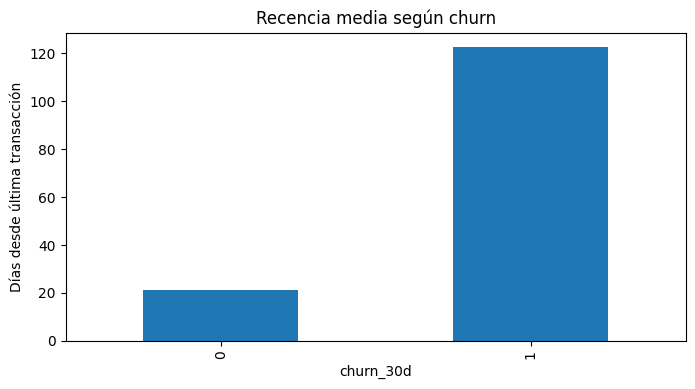

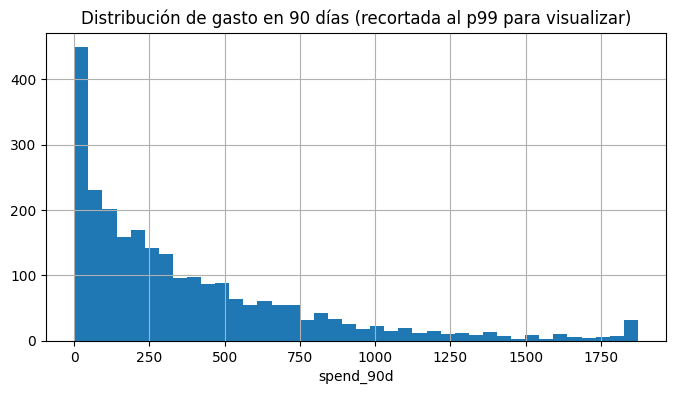

In [12]:
# El primer gráfico compara una señal con el target solo para EDA.
# El segundo recorta al percentil 99 ÚNICAMENTE para visualizar la cola;
# no alteramos `features["spend_90d"]` ni los datos usados por el modelo.

# 19. Visualizaciones sencillas para explicar señal y distribución
fig, ax = plt.subplots(figsize=(8,4))
features.groupby("churn_30d")["recency_days"].mean().plot(kind="bar", ax=ax)
ax.set_title("Recencia media según churn")
ax.set_xlabel("churn_30d")
ax.set_ylabel("Días desde última transacción")
plt.show()

fig, ax = plt.subplots(figsize=(8,4))
features["spend_90d"].clip(upper=features["spend_90d"].quantile(.99)).hist(bins=40, ax=ax)
ax.set_title("Distribución de gasto en 90 días (recortada al p99 para visualizar)")
ax.set_xlabel("spend_90d")
plt.show()

# 20. Data leakage: el error más peligroso

```text
PREDICCIÓN en t0
│
├── Información conocida en t0 ─────────────→ SÍ puede ser feature
└── Información ocurrida después de t0 ─────→ NO puede ser feature
```

Ejemplos de leakage:

- usar “fecha de cancelación” para predecir cancelación;
- imputar con la mediana calculada sobre **train + test**;
- seleccionar variables mirando primero todo el target;
- construir promedios históricos que incluyan eventos posteriores al `snapshot`;
- normalizar antes de separar entrenamiento y prueba.

**Solución:** primero definir el tiempo y el split; después ajustar transformaciones solo con entrenamiento. Por eso usaremos un `Pipeline`.

### Cuatro clases de leakage que hay que distinguir

1. **Target leakage:** una variable contiene directa o indirectamente el resultado.
2. **Temporal leakage:** usamos información que ocurre después del instante de predicción.
3. **Train–test contamination:** calculamos imputadores, escalas o selección de variables usando también el test.
4. **Group leakage:** observaciones de la misma entidad aparecen simultáneamente en train y test cuando deberían mantenerse juntas.

El `Pipeline` resuelve principalmente el tercer problema; los otros requieren diseñar correctamente la población, el tiempo y el split.

In [13]:
# X contiene predictores e y contiene exclusivamente el target.
# Quitamos `customer_id` porque es identificador, no comportamiento, y `signup_date`
# porque ya fue transformada en antigüedad y componentes cíclicos.
# `stratify=y` conserva aproximadamente la prevalencia del target en train/test.

# 21. Preparar X e y
TARGET = CONFIG["target"]

X = features.drop(columns=[TARGET])
y = features[TARGET].astype(int)

# customer_id identifica, pero no describe comportamiento.
# signup_date ya fue transformada a features temporales.
X_model = X.drop(columns=["customer_id","signup_date"])

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=CONFIG["test_size"],
    stratify=y,
    random_state=CONFIG["seed"]
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Prevalencia churn train:", y_train.mean().round(4))
print("Prevalencia churn test :", y_test.mean().round(4))

Train: (1875, 38) Test: (625, 38)
Prevalencia churn train: 0.2949
Prevalencia churn test : 0.2944


# 22. Pipeline de preprocesamiento

Para columnas numéricas:

$$
z_i = \frac{x_i - \mathrm{mediana}(x)}{IQR(x)}
$$

Usaremos `RobustScaler`, basado en mediana y rango intercuartílico (**IQR — Interquartile Range**), menos sensible a valores extremos que la estandarización clásica.

Para categorías usaremos **OHE — One-Hot Encoding**.

El pipeline aprende imputación, escalado y codificación **solo en entrenamiento**.

### Anatomía del preprocesamiento

Para variables numéricas:

1. `SimpleImputer(strategy="median")` aprende la mediana **solo en train**.
2. `add_indicator=True` añade una bandera que informa al modelo de que el valor original faltaba.
3. `RobustScaler` centra por mediana y escala mediante el rango intercuartílico, por lo que es menos sensible a colas extremas.

Para variables categóricas:

1. se imputa la categoría más frecuente;
2. `OneHotEncoder` crea indicadores binarios;
3. `handle_unknown="ignore"` evita que una categoría nueva en producción rompa el pipeline;
4. `min_frequency` reduce categorías extremadamente raras.

La ventaja central no es solo comodidad: **las mismas reglas quedan encapsuladas junto al modelo**.

In [14]:
# `make_models` construye estimadores que comparten el mismo preprocesamiento.
# Esto hace que la comparación sea más justa: cambia el algoritmo, no la preparación.
# `run_and_log` entrena cada pipeline, evalúa sobre el mismo test y persiste métricas.

# 23. Crear y entrenar modelos
from modeling import make_models, run_and_log

models, numeric_cols, categorical_cols = make_models(X_train, seed=CONFIG["seed"])

print("Numéricas:", len(numeric_cols))
print("Categóricas:", categorical_cols)

results = run_and_log(
    models,
    X_train, y_train,
    X_test, y_test,
    ROOT/"artifacts/experiment_results.csv"
)

display(results)

Numéricas: 34
Categóricas: ['region', 'plan', 'acquisition_channel', 'plan_x_channel']


,roc_auc,pr_auc,accuracy,precision,recall,f1,model,fit_seconds
1,0.806529,0.725916,0.7904,0.668790,0.570652,0.615836,random_forest,7.144368
0,0.800959,0.724465,0.7360,0.542601,0.657609,0.594595,logistic_regression,0.924053


# 24. Cómo leer las métricas

- **Accuracy:** proporción total de aciertos. Puede engañar si hay fuerte desbalance.
- **Precision:** de todas las alertas positivas, cuántas eran realmente positivas.
- **Recall:** de todos los positivos reales, cuántos detectamos.
- **F1:** equilibrio entre precisión y recall.
- **ROC-AUC:** probabilidad de ordenar un positivo por encima de un negativo elegido al azar.
- **PR-AUC:** resume precisión y recall; suele ser más informativa en problemas con clase positiva escasa.

No existe una “mejor métrica universal”. Debe alinearse con el costo de falsos positivos y falsos negativos.

### Matriz de confusión y métricas

```text
                    PREDICCIÓN
                 0              1
REAL 0       verdadero      falso
             negativo       positivo

REAL 1       falso          verdadero
             negativo       positivo
```

De ahí salen:

$$Precision = \frac{TP}{TP+FP}$$

$$Recall = \frac{TP}{TP+FN}$$

$$F1 = 2\frac{Precision\cdot Recall}{Precision+Recall}$$

El umbral 0.5 no es una ley. En producción debe elegirse según costos, capacidad operativa y tolerancia a falsos positivos/falsos negativos.

Mejor modelo: random_forest


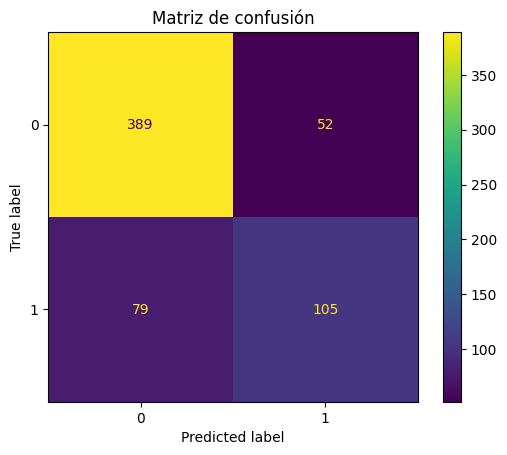

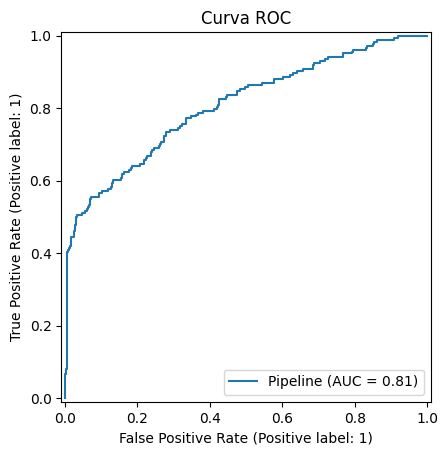

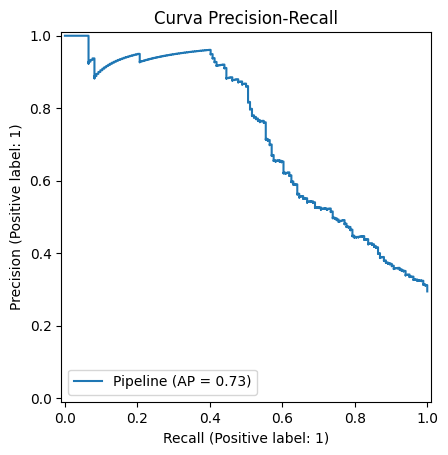

In [15]:
# Elegimos por ROC-AUC solo como criterio pedagógico explícito.
# La matriz de confusión usa el umbral por defecto del estimador (0.5);
# las curvas ROC y PR evalúan el ranking a través de múltiples umbrales.

# 25. Elegir el mejor modelo por ROC-AUC
best_name = results.iloc[0]["model"]
best_model = models[best_name]

print("Mejor modelo:", best_name)

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)
plt.title("Matriz de confusión")
plt.show()

RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title("Curva ROC")
plt.show()

PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test)
plt.title("Curva Precision-Recall")
plt.show()

# 26. Validación cruzada estratificada

**Stratified K-Fold** divide los datos en $K$ bloques preservando aproximadamente la proporción de clases.

```text
Fold 1: train train train test
Fold 2: train train test  train
Fold 3: train test  train train
Fold 4: test  train train train
```

Esto permite estimar la variabilidad del desempeño y no depender de una única partición.

### ¿Por qué estratificar?

Si la clase positiva representa, por ejemplo, 12 % de la población, una partición aleatoria pequeña podría dejar 8 % en un fold y 16 % en otro. La estratificación intenta conservar aproximadamente la prevalencia en cada partición.

Esto **no corrige desbalance**; solo hace más comparables los folds.

In [16]:
# La validación cruzada se ejecuta SOLO sobre el conjunto de entrenamiento.
# El test externo se reserva para una evaluación final y no debe usarse
# repetidamente para decidir arquitectura o hiperparámetros.

# 27. Cross-Validation del modelo seleccionado
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

print("ROC-AUC por fold:", np.round(cv_scores, 4))
print("Media:", round(cv_scores.mean(), 4))
print("Desv. estándar:", round(cv_scores.std(), 4))

ROC-AUC por fold: [0.8601 0.7463 0.8171 0.8424 0.7955]
Media: 0.8123
Desv. estándar: 0.0396


# 28. Importancia por permutación

La **Permutation Importance** responde:

> “¿Cuánto empeora el modelo si rompo aleatoriamente la relación entre una feature y el target?”

Ventaja: funciona con cualquier estimador.  
Precaución: variables muy correlacionadas pueden repartirse la importancia entre sí.

### Qué significa “permutar”

Para una feature $X_j$:

1. medimos el desempeño original;
2. desordenamos aleatoriamente solo $X_j$;
3. mantenemos intactas las demás columnas;
4. volvemos a medir;
5. repetimos varias veces.

Si el ROC-AUC cae mucho, esa feature contenía señal útil. Si no cae, el modelo puede estar prescindiendo de ella o su información puede estar duplicada en variables correlacionadas.

,feature,importance_mean,importance_std
10,monetary_total,0.006570,0.001786
9,txn_count,0.006140,0.001932
16,units_total,0.005498,0.002519
21,txn_count_90d,0.003358,0.001259
23,units_90d,0.002757,0.002170
36,log_spend_90d,0.002340,0.001386
17,recency_days,0.001793,0.002778
15,weekend_share,0.001661,0.001355
33,engagement_velocity,0.001641,0.001237
28,avg_resolution_hours_90d,0.001621,0.000122


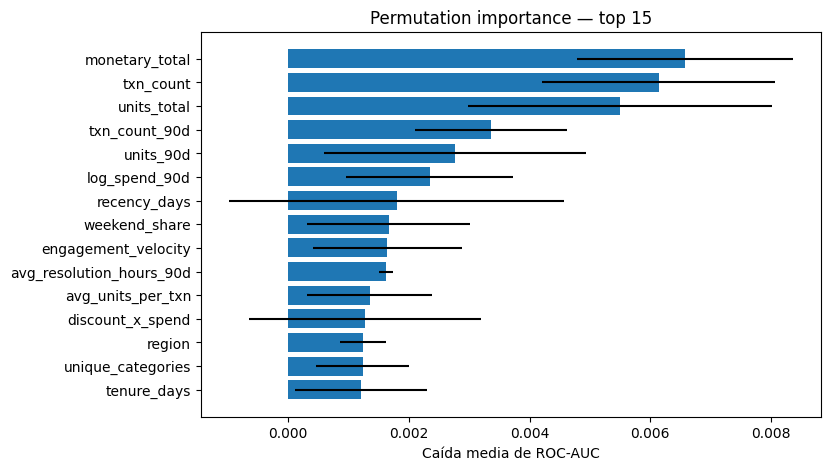

In [18]:
# Cada repetición rompe una columna diferente manteniendo las demás intactas.
# Medimos cuánto cae ROC-AUC: mayor caída -> mayor dependencia del modelo.
# `n_repeats` reduce la variabilidad de una sola permutación aleatoria.

# 29. Importancia por permutación sobre columnas originales
perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=8,
    random_state=SEED,
    n_jobs=-1
)

importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False)

display(importance.head(20))

top = importance.head(15).sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(8,5))
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
ax.set_title("Permutation importance — top 15")
ax.set_xlabel("Caída media de ROC-AUC")
plt.show()

# 30. Mini‑proyecto 2: relaciones y agregaciones

Una tabla de eventos suele tener granularidad “una fila por evento”. El modelo de churn necesita “una fila por cliente”.

```text
transactions
customer_id | transaction_id | amount | date
     101    |       1        |  50    | ...
     101    |       2        |  75    | ...
     102    |       3        |  20    | ...
          │
          ▼ GROUP BY customer_id
customer_features
customer_id | txn_count | total_spend | avg_ticket
     101    |     2     |    125      | 62.5
     102    |     1     |     20      | 20.0
```

Este patrón aparece en banca, retail, educación, salud, telecomunicaciones, logística y plataformas digitales.

### De eventos a entidades

Este paso se denomina a menudo **feature aggregation**. Una misma tabla de transacciones puede generar diferentes matrices según el problema:

```text
predicción por cliente  → groupby(customer_id)
predicción por tienda   → groupby(store_id)
predicción por día      → groupby(date)
predicción cliente-mes  → groupby(customer_id, month)
```

La granularidad del target y la granularidad de las features deben ser compatibles.

In [20]:
# `groupby(customer_id)` cambia la granularidad:
# de una fila por transacción pasamos a una fila por cliente.
# Cada agregación responde una pregunta distinta: frecuencia, valor medio,
# gasto acumulado o diversidad de categorías.

# 31. Construcción manual de una agregación para practicar
practice = (
    transactions
    .groupby("customer_id")
    .agg(
        compras=("transaction_id","count"),
        gasto_total=("amount","sum"),
        ticket_medio=("amount","mean"),
        categorias=("category","nunique"),
    )
    .reset_index()
)

display(practice.head())

,customer_id,compras,gasto_total,ticket_medio,categorias
0,100000,8,331.315971,41.414496,5
1,100001,6,1014.964386,169.160731,3
2,100002,9,1212.148469,134.683163,4
3,100003,7,790.861744,112.980249,4
4,100004,16,757.940255,47.371266,5


# 32. Mini‑proyecto 3: features temporales tipo forecasting

Para series temporales son frecuentes:

- **Lag:** valor observado $k$ periodos antes.
- **Rolling mean:** promedio móvil de una ventana.
- **Rolling std:** volatilidad reciente.
- **Difference:** cambio respecto al periodo anterior.

$$
lag_k(t)=y_{t-k}
$$

$$
MA_k(t)=\frac{1}{k}\sum_{i=1}^{k}y_{t-i}
$$

La palabra clave es **pasado**. Si una ventana incluye el propio futuro que queremos predecir, aparece leakage.

### Regla temporal fundamental

Para predecir $y_t$, una media móvil válida usa únicamente observaciones anteriores:

$$lag_k(t)=y_{t-k}$$

$$MA_k(t)=\frac{1}{k}\sum_{i=1}^{k}y_{t-i}$$

Por eso en el código aparece primero `shift(1)` y después `rolling(7)`. Si hiciéramos `rolling(7)` directamente sobre `sales`, la ventana incluiría $y_t$ y contaminaría la feature con el valor contemporáneo que intentamos anticipar.

In [21]:
# `asfreq("D", fill_value=0)` crea explícitamente días sin ventas.
# Para rolling_mean_7 y rolling_std_7 hacemos `shift(1)` ANTES de `rolling(7)`:
# así la feature del día t usa únicamente t-1,...,t-7 y nunca el propio y_t.

# 33. Ejemplo temporal agregado por día
daily = (
    transactions
    .assign(transaction_date=lambda d: pd.to_datetime(d["transaction_date"]).dt.floor("D"))
    .groupby("transaction_date")["amount"]
    .sum()
    .sort_index()
    .asfreq("D", fill_value=0)
    .rename("sales")
    .to_frame()
)

daily["lag_1"] = daily["sales"].shift(1)
daily["lag_7"] = daily["sales"].shift(7)
daily["rolling_mean_7"] = daily["sales"].shift(1).rolling(7).mean()
daily["rolling_std_7"] = daily["sales"].shift(1).rolling(7).std()
daily["diff_1"] = daily["sales"].diff(1)

display(daily.tail(12))

,sales,lag_1,lag_7,rolling_mean_7,rolling_std_7,diff_1
transaction_date,,,,,,
2026-08-20,12796.635857,10493.055000,11659.977767,10062.809935,1160.345684,2303.580856
2026-08-21,12887.376250,12796.635857,9961.753122,10225.189663,1461.546070,90.740393
2026-08-22,11750.141069,12887.376250,11025.457026,10643.135824,1761.239486,-1137.235181
2026-08-23,11429.442314,11750.141069,10130.338040,10746.662116,1808.132297,-320.698755
2026-08-24,12938.979652,11429.442314,8707.743729,10932.248440,1800.985464,1509.537339
2026-08-25,9668.235024,12938.979652,8461.344865,11536.710715,1632.085491,-3270.744629
2026-08-26,10031.125990,9668.235024,10493.055000,11709.123595,1278.505716,362.890967
2026-08-27,10735.674538,10031.125990,12796.635857,11643.133736,1360.994226,704.548547
2026-08-28,10221.665656,10735.674538,12887.376250,11348.710691,1290.991367,-514.008881


# 34. Mini‑proyecto 4: detección de deriva con PSI

**Data drift** significa que la distribución de una entrada cambió entre el conjunto de referencia y datos nuevos.

El **PSI** usa:

$$
PSI=\sum_i (a_i-e_i)\ln\left(\frac{a_i}{e_i}\right)
$$

donde:

- $e_i$: proporción esperada en el intervalo $i$;
- $a_i$: proporción actual.

Guía heurística frecuente:

```text
PSI < 0.10      cambio pequeño
0.10–0.25       revisar
> 0.25          cambio importante
```

Estos umbrales son orientativos, no leyes universales.

### Interpretación del PSI

El PSI compara **distribuciones**, no desempeño predictivo. Puede detectar que la población cambió aunque todavía no conozcamos las etiquetas verdaderas.

$$PSI=\sum_i (a_i-e_i)\ln\left(\frac{a_i}{e_i}\right)$$

Un PSI alto no demuestra automáticamente que el modelo fallará; indica que alguna entrada se alejó de la referencia y merece diagnóstico. Para detectar **concept drift** necesitamos evaluar cómo cambió la relación entre features y target.

In [22]:
# Simulamos un desplazamiento controlado para practicar monitoreo:
# recencia aumenta ~18 % y gasto cae ~18 % en promedio.
# PSI compara la muestra de referencia con esta población futura simulada.

# 35. Simular datos futuros con drift
from monitoring import population_stability_index

rng = np.random.default_rng(SEED)
future_recency = features["recency_days"].to_numpy() * rng.normal(1.18, 0.08, len(features))
future_spend = features["spend_90d"].to_numpy() * rng.normal(0.82, 0.12, len(features))

psi_recency = population_stability_index(features["recency_days"], future_recency)
psi_spend = population_stability_index(features["spend_90d"], future_spend)

pd.DataFrame({
    "feature": ["recency_days","spend_90d"],
    "PSI": [psi_recency, psi_spend]
})

,feature,PSI
0,recency_days,0.056840
1,spend_90d,0.031244


# 36. Reproducibilidad: qué guardar

```text
EXPERIMENTO REPRODUCIBLE
├── Código
├── Configuración
├── Seed
├── Dataset o referencia exacta
├── Hash del dataset
├── Versiones de paquetes
├── Split
├── Pipeline
├── Modelo
├── Métricas
└── Fecha / identificador de corrida
```

Reproducibilidad **no** significa solo “poner `random_state=42`”.

### Tres niveles de reproducibilidad

- **Repetibilidad:** mismo código + mismos datos + mismo entorno → mismo resultado.
- **Reproducibilidad computacional:** otra persona puede reconstruir el resultado con artefactos y dependencias registradas.
- **Robustez:** la conclusión se mantiene bajo decisiones razonables alternativas.

La semilla ayuda al primer nivel, pero no sustituye versionado de datos, entorno ni definición de población.

In [23]:
# Guardamos la matriz procesada para congelar exactamente qué entró al experimento.
# SHA-256 resume los bytes del archivo: una modificación, aunque sea mínima,
# cambia el hash con probabilidad práctica abrumadora.
# El manifiesto registra versiones del entorno para reconstruir dependencias.

# 37. Guardar dataset procesado y calcular SHA-256
from repro import sha256_file, write_environment_manifest
from modeling import save_pipeline

processed_path = ROOT/"data/processed/customer_features.csv"
features.to_csv(processed_path, index=False)

data_hash = sha256_file(processed_path)
print("SHA-256:", data_hash)

manifest_path = write_environment_manifest(ROOT/"artifacts/environment_manifest.json")
print("Manifest:", manifest_path)

SHA-256: e2c19589655c283996b8b439b5a06556d84d28ef94d915b39da692f635a2fde9
Manifest: /content/drive/MyDrive/GEM_EDUCA/gem_s03/artifacts/environment_manifest.json


In [24]:
# Serializamos el PIPELINE completo, no solo el estimador final.
# Esto conserva imputación, escalado, OHE y modelo como una sola unidad.
# La comparación `np.allclose` verifica que recargar no cambie las probabilidades.

# 38. Guardar y recargar el pipeline completo
model_path = save_pipeline(best_model, ROOT/f"models/{best_name}.joblib")
print("Modelo guardado en:", model_path)

import joblib
reloaded_model = joblib.load(model_path)

p1 = best_model.predict_proba(X_test.iloc[:5])[:,1]
p2 = reloaded_model.predict_proba(X_test.iloc[:5])[:,1]

assert np.allclose(p1, p2)
print("OK: el modelo recargado reproduce las mismas probabilidades.")

Modelo guardado en: /content/drive/MyDrive/GEM_EDUCA/gem_s03/models/random_forest.joblib
OK: el modelo recargado reproduce las mismas probabilidades.


# 39. Registro de experimento

Un registro mínimo debe permitir responder:

```text
¿Qué ejecuté?
├── modelo
├── configuración
├── datos
├── hash
├── métricas
└── artefacto final
```

En equipos más grandes esto puede evolucionar hacia herramientas como MLflow, Weights & Biases o un registro institucional.

### Qué debe responder un registro de corrida

Un buen registro permite reconstruir la genealogía del resultado:

```text
resultado
├── qué modelo lo produjo
├── con qué hiperparámetros
├── sobre qué versión de datos
├── con qué código/entorno
├── con qué split
└── qué métricas obtuvo
```

Si no podemos responder esas preguntas, comparar dos experimentos se vuelve ambiguo.

In [25]:
# Registramos la hora en UTC para evitar ambigüedad entre zonas horarias.
# El JSON conecta configuración, hash de datos, modelo y métricas en una sola corrida.

# 40. Crear metadata de la corrida
from datetime import datetime, timezone

run_metadata = {
    "project": CONFIG["project_name"],
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "seed": CONFIG["seed"],
    "snapshot_date": CONFIG["snapshot_date"],
    "data_sha256": data_hash,
    "best_model": best_name,
    "model_path": str(model_path),
    "metrics": results.set_index("model").loc[best_name].to_dict(),
}

metadata_path = ROOT/"artifacts/run_metadata.json"
metadata_path.write_text(json.dumps(run_metadata, indent=2, default=str), encoding="utf-8")

display(pd.Series(run_metadata))

,0
project,GEM_EDUCA_S03
created_utc,2026-10-12T02:32:45.860974+00:00
seed,42
snapshot_date,2026-09-01
data_sha256,e2c19589655c283996b8b439b5a06556d84d28ef94d915...
best_model,random_forest
model_path,/content/drive/MyDrive/GEM_EDUCA/gem_s03/model...
metrics,"{'roc_auc': 0.8065291333924873, 'pr_auc': 0.72..."


# 41. Pruebas rápidas del pipeline de features

Las pruebas automatizadas sirven para detectar errores silenciosos.

Ejemplos:

- una PK debe seguir siendo única;
- ningún conteo puede ser negativo;
- no deben aparecer fechas posteriores al snapshot;
- la matriz final debe tener una fila por cliente;
- las features esperadas deben existir.

### `assert` como contrato ejecutable

`assert condición` detiene la ejecución cuando una expectativa estructural deja de cumplirse. No reemplaza una suite completa de pruebas, pero convierte supuestos importantes en **contratos verificables**.

Ejemplo: “debe existir una fila por cliente” deja de ser una frase en documentación y se transforma en una condición que el programa comprueba.

In [26]:
# Estos tests expresan invariantes del dominio y de la ingeniería de features.
# Si una condición deja de cumplirse, preferimos fallar aquí y no entrenar
# silenciosamente sobre una matriz corrupta.

# 42. Smoke tests / unit tests mínimos
assert features["customer_id"].is_unique
assert len(features) == len(customers)
assert (features["txn_count"] >= 0).all()
assert (features["tickets_90d"] >= 0).all()
assert features["churn_30d"].isin([0,1]).all()

required_features = {
    "recency_days", "txn_count_30d", "spend_90d",
    "support_per_txn_90d", "spend_trend_ratio",
    "signup_month_sin", "signup_month_cos"
}
assert required_features.issubset(features.columns)

print("Todos los tests pasaron.")

Todos los tests pasaron.


# 43. Árbol de diagnóstico cuando un modelo falla

```text
¿El modelo rinde mal?
│
├── ¿Los datos son correctos?
│   ├── PK/FK
│   ├── faltantes
│   ├── etiquetas
│   └── fechas
│
├── ¿Existe señal predictiva?
│   ├── features débiles
│   ├── target ruidoso
│   └── problema mal definido
│
├── ¿Existe leakage?
│   ├── feature futura
│   ├── preprocesamiento antes del split
│   └── agregación temporal incorrecta
│
├── ¿El split representa producción?
│   ├── aleatorio
│   ├── temporal
│   ├── por grupo
│   └── por entidad
│
├── ¿La métrica es adecuada?
│   ├── accuracy
│   ├── F1
│   ├── ROC-AUC
│   └── PR-AUC
│
└── ¿Cambió la distribución?
    ├── data drift
    ├── concept drift
    └── cambio de política / proceso
```

# 44. Desafíos de clase

### Nivel 1 — Datos
1. Introducir duplicados deliberadamente y construir una regla para detectarlos.
2. Crear una FK inválida y comprobar que `validate_relations` la rechaza.
3. Añadir una nueva categoría de plan y observar el comportamiento de `OneHotEncoder(handle_unknown="ignore")`.

### Nivel 2 — Features
1. Crear `avg_spend_per_unit`.
2. Crear ventanas de 7, 14 y 60 días.
3. Crear una feature de aceleración:
   $$
   \frac{spend_{0-30}}{spend_{31-60}+1}
   -
   \frac{spend_{31-60}}{spend_{61-90}+1}
   $$
4. Crear una feature que combine severidad de soporte y recencia.

### Nivel 3 — Reproducibilidad
1. Cambiar `seed` y comparar resultados.
2. Modificar una fila del CSV y comprobar que cambia SHA-256.
3. Guardar dos corridas con distinto identificador y comparar métricas.

### Nivel 4 — Pensamiento crítico
1. Diseñar una feature que **parezca útil pero sea leakage**.
2. Explicar por qué debe excluirse.
3. Proponer un split temporal para un sistema que se reentrena mensualmente.

# **Desafíos de clase**

### 1.1. Inserción y Detección de Duplicados (Integridad de Primary Key)

**Objetivo:** Demostrar la importancia de las reglas de calidad de datos comprobando qué sucede cuando se vulnera la unicidad de una clave primaria (PK) y cómo el sistema debe reaccionar para evitar la multiplicación errónea de registros (Data Leakage y distorsión estadística).

**Metodología:**
1. **Inyección del error:** Se toma un registro existente de la tabla maestra `customers` (que representa la granularidad base de un cliente único) y se concatena intencionalmente al final del *DataFrame* para generar un duplicado exacto.
2. **Regla de detección:** Se diseña una función de validación que evalúa la propiedad `.is_unique` sobre la columna que actúa como Primary Key (`customer_id`).
3. **Control de excepciones:** Si la validación detecta que la clave no es única, el flujo arroja un `ValueError` detallando el problema. Esto simula un cortafuegos en un pipeline de datos real (ETL/ELT) que previene que los datos corruptos pasen a la fase de *Feature Engineering*.

In [44]:
# ==========================================
# DESAFÍO 1.1: Duplicados deliberados
# ==========================================
import pandas as pd

# 1. Introducir un duplicado deliberadamente en la tabla 'customers'
# Tomamos el primer cliente y lo volvemos a concatenar al final
cliente_duplicado = customers.iloc[[0]].copy()
customers_corrupto = pd.concat([customers, cliente_duplicado], ignore_index=True)

print(f"Filas originales en customers: {len(customers)}")
print(f"Filas tras inyectar duplicado: {len(customers_corrupto)}\n")

# 2. Construir la regla para detectarlo
def check_primary_key_uniqueness(df, pk_column):
    """
    Verifica si una columna cumple la regla de unicidad de Clave Primaria.
    Falla y levanta un error si encuentra valores duplicados.
    """
    if not df[pk_column].is_unique:
        num_duplicados = df.duplicated(subset=[pk_column], keep=False).sum()
        raise ValueError(f"🚨 ALERTA DE CALIDAD: La PK '{pk_column}' no es única. Contiene {num_duplicados} filas afectadas por duplicidad.")

    print(f"✅ VALIDACIÓN OK: La columna '{pk_column}' es estrictamente única.")
    return True

# 3. Comprobar la regla (usamos try-except para que el notebook no se detenga abruptamente en clase)
try:
    print("Evaluando tabla corrupta...")
    check_primary_key_uniqueness(customers_corrupto, "customer_id")
except ValueError as e:
    print(e)

Filas originales en customers: 2500
Filas tras inyectar duplicado: 2501

Evaluando tabla corrupta...
🚨 ALERTA DE CALIDAD: La PK 'customer_id' no es única. Contiene 2 filas afectadas por duplicidad.


### 1.2. Inyección de FK Inválida y Validación de Integridad Referencial

**Objetivo:** Simular un fallo de integridad referencial donde un evento transaccional hace referencia a un cliente inexistente, y demostrar cómo la función del sistema bloquea esta inconsistencia antes de llegar al modelado.

**Metodología:**
1. **Inyección del error:** Se crea una copia de la tabla `transactions` y se altera intencionalmente el identificador de un cliente (`customer_id`) cambiándolo por un valor ficticio que no existe en la tabla maestra (por ejemplo, `999999`). Esto simula un "registro huérfano" (FK inválida).
2. **Regla de detección:** Se utiliza la función `validate_relations` ya definida en `features.py`. Esta función evalúa mediante operaciones de conjuntos que todos los `customer_id` de la tabla transaccional sean un subconjunto estricto (`.issubset()`) de los IDs en la tabla `customers`.
3. **Control de excepciones:** Al procesar el registro con el ID inventado, el sistema detecta que el conjunto de transacciones contiene elementos ajenos al conjunto maestro y levanta un `AssertionError`, impidiendo que la matriz de características se contamine con información huérfana.

In [45]:
# ==========================================
# DESAFÍO 1.2: Clave Foránea (FK) Inválida
# ==========================================
from features import validate_relations

# 1. Crear una copia de transacciones e inyectar el error
transactions_corrupta = transactions.copy()

# Alteramos deliberadamente el customer_id de la primera fila con un valor inexistente
id_fantasma = 999999
transactions_corrupta.loc[0, "customer_id"] = id_fantasma

print(f"ID inyectado en la tabla de transacciones: {id_fantasma}")
print(f"¿Existe el cliente {id_fantasma} en la tabla maestra 'customers'?: {id_fantasma in customers['customer_id'].values}\n")

# 2. Ejecutar la regla y comprobar el rechazo
try:
    print("Ejecutando evaluación de integridad PK/FK...")
    # Pasamos la tabla transaccional corrupta a la función
    validate_relations(customers, transactions_corrupta, support)
    print("✅ VALIDACIÓN OK: Integridad referencial correcta.")
except AssertionError as e:
    print(f"🚨 ALERTA DE INTEGRIDAD: Flujo detenido. Motivo: {e}")

ID inyectado en la tabla de transacciones: 999999
¿Existe el cliente 999999 en la tabla maestra 'customers'?: False

Ejecutando evaluación de integridad PK/FK...
🚨 ALERTA DE INTEGRIDAD: Flujo detenido. Motivo: FK inválida en transactions.


### 1.3. Robustez del One-Hot Encoder (Categorías Desconocidas)

**Objetivo:** Validar que el pipeline de preprocesamiento no colapsa en producción cuando recibe una categoría que nunca vio durante la fase de entrenamiento.

**Metodología:**
1. **Inyección del error:** Tomamos una observación del conjunto de prueba (`X_test`) y alteramos el valor de la variable `plan` a una categoría inexistente, como `"Elite"`.
2. **Regla de procesamiento:** En la arquitectura del proyecto, el pipeline categórico cuenta con un `OneHotEncoder` configurado con el hiperparámetro `handle_unknown="ignore"`.
3. **Resultado:** Al transformar este registro, el codificador no emitirá un `ValueError` (que es el comportamiento por defecto de scikit-learn). En su lugar, absorberá el error silenciosamente asignando el valor `0` a todas las columnas binarias de los planes conocidos (`Basic`, `Plus`, `Pro`), permitiendo que el sistema siga prediciendo sin interrumpir el servicio.

In [46]:
# ==========================================
# DESAFÍO 1.3: Nueva categoría en el OHE
# ==========================================
import pandas as pd

# 1. Tomamos una observación real de nuestro conjunto de prueba (X_test)
x_nuevo = X_test.iloc[[0]].copy()
plan_original = x_nuevo["plan"].values[0]

# Inyectamos una categoría de plan que el modelo jamás ha visto
x_nuevo["plan"] = "Elite"
plan_corrupto = x_nuevo["plan"].values[0]

print(f"Plan original del cliente: {plan_original}")
print(f"Plan modificado (categoría nueva): {plan_corrupto}\n")

# 2. Extraemos el preprocesador ya ajustado desde nuestro mejor modelo
preprocesador = best_model.named_steps["prep"]

# 3. Transformamos el dato modificado
try:
    print("Pasando el registro con la categoría 'Elite' por el preprocesador...")
    # Si falla, arrojará un error. Si funciona, generará el array numérico.
    x_transformado = preprocesador.transform(x_nuevo)
    print("✅ VALIDACIÓN OK: El pipeline no colapsó. La categoría desconocida fue ignorada y convertida a ceros.")
    print(f"Forma de la matriz transformada: {x_transformado.shape}")
except Exception as e:
    print(f"🚨 ERROR: El pipeline falló abruptamente. Motivo: {e}")

Plan original del cliente: Basic
Plan modificado (categoría nueva): Elite

Pasando el registro con la categoría 'Elite' por el preprocesador...
✅ VALIDACIÓN OK: El pipeline no colapsó. La categoría desconocida fue ignorada y convertida a ceros.
Forma de la matriz transformada: (1, 61)


### 2.1. Creación de nueva característica: Gasto promedio por unidad (`avg_spend_per_unit`)

**Objetivo:** Crear una variable (feature) matemática que capture el comportamiento de gasto relativo del cliente, específicamente cuánto gasta en promedio por cada artículo físico que compra.

**Metodología:**
1. **Lógica de negocio:** Un cliente que gasta 100 en 1 unidad tiene un perfil de consumo muy diferente (ticket de alto valor) al de un cliente que gasta 100 en 50 unidades (comprador de volumen/productos económicos). Para el algoritmo de Machine Learning, darle esta relación ya calculada ahorra tiempo de entrenamiento y extrae una señal predictiva fuerte.
2. **Operación:** Se divide la columna de gasto total (`monetary_total`) entre la columna de unidades totales (`units_total`).
3. **Seguridad matemática:** Como regla estricta en *Feature Engineering*, jamás debemos dividir directamente sin controlar los ceros. Si un cliente no tiene compras en su historial, `units_total` será 0. Dividir entre cero arrojará un valor nulo (`NaN`) o infinito (`inf`) que romperá los modelos posteriores. Usaremos una función condicional (como `np.where` en NumPy) para que, si las unidades son 0, el gasto promedio sea automáticamente 0.

In [47]:
# ==========================================
# DESAFÍO 2.1: Crear avg_spend_per_unit
# ==========================================
import numpy as np

# 1. Calculamos el ratio protegiéndonos de la división por cero
features["avg_spend_per_unit"] = np.where(
    features["units_total"] > 0,
    features["monetary_total"] / features["units_total"],
    0  # Valor por defecto si units_total es 0
)

# 2. Validamos los resultados con un resumen estadístico
print("Resumen estadístico de 'avg_spend_per_unit':")
print(features["avg_spend_per_unit"].describe().round(2))
print("-" * 50)

# 3. Mostramos las primeras filas para verificar el cálculo lógicamente
columnas_revision = ["customer_id", "monetary_total", "units_total", "avg_spend_per_unit"]
display(features[columnas_revision].head())

Resumen estadístico de 'avg_spend_per_unit':
count    2500.00
mean       42.99
std        26.11
min         0.00
25%        25.47
50%        38.01
75%        55.90
max       210.21
Name: avg_spend_per_unit, dtype: float64
--------------------------------------------------


,customer_id,monetary_total,units_total,avg_spend_per_unit
0,100000,320.128789,13.0,24.625291
1,100001,988.258989,13.0,76.019922
2,100002,1136.905130,19.0,59.837112
3,100003,722.563993,11.0,65.687636
4,100004,730.413480,27.0,27.052351


### 2.2. Construcción de Ventanas Temporales (7, 14 y 60 días)

**Objetivo:** Capturar el nivel de "frescura" e intensidad reciente en el comportamiento del cliente. Las ventanas cortas (7 y 14 días) detectan interacciones muy recientes (útiles para predecir retención a corto plazo), mientras que la de 60 días sirve de puente entre el corto plazo (30 días) y el mediano plazo (90 días).

**Metodología:**
1. **Filtro Temporal:** Se calcula la cantidad de días de antigüedad de cada transacción respecto a la fecha del snapshot (nuestra "fotografía" del presente que evita el Data Leakage).
2. **Segmentación:** Se filtran las transacciones que ocurrieron estrictamente entre 1 y $X$ días atrás ($X$ siendo 7, 14 o 60).
3. **Agregación (Group By):** Para cada ventana de tiempo y por cada cliente (customer_id), se suma el gasto neto, se suman las unidades compradas y se cuenta el número de transacciones.
4. **Cruce (Merge) e Imputación:** Estas nuevas tablas se cruzan con la matriz principal de características (features) mediante un LEFT JOIN. Si un cliente no compró nada en los últimos 7 días, la agregación arrojará nulo (NaN); por lo tanto, es crítico imputar estos valores con 0.

In [48]:
# ==========================================
# DESAFÍO 2.2: Crear ventanas de 7, 14 y 60 días
# ==========================================
import pandas as pd

# 1. Recuperamos la fecha del snapshot y preparamos los datos transaccionales
snapshot = pd.Timestamp(CONFIG["snapshot_date"])
tx = transactions.copy()
tx["transaction_date"] = pd.to_datetime(tx["transaction_date"])

# Filtramos estrictamente eventos pasados para evitar Leakage
tx = tx[tx["transaction_date"] < snapshot].copy()
tx["days_ago"] = (snapshot - tx["transaction_date"]).dt.days
tx["net_amount"] = tx["amount"] * (1 - tx["discount_pct"])

# 2. Función auxiliar para generar ventanas de forma modular
def crear_ventana_temporal(df_tx, dias):
    """Filtra transacciones de los últimos 'dias' y agrega métricas por cliente."""
    ventana = df_tx[df_tx["days_ago"].between(1, dias)]
    agregado = ventana.groupby("customer_id").agg(
        **{
            f"txn_count_{dias}d": ("transaction_id", "count"),
            f"spend_{dias}d": ("net_amount", "sum"),
            f"units_{dias}d": ("units", "sum"),
        }
    ).reset_index()
    return agregado

# 3. Calculamos las agregaciones para 7, 14 y 60 días
w7 = crear_ventana_temporal(tx, 7)
w14 = crear_ventana_temporal(tx, 14)
w60 = crear_ventana_temporal(tx, 60)

# 4. Unimos las nuevas features a nuestra matriz principal 'features'
for w_df in [w7, w14, w60]:
    features = features.merge(w_df, on="customer_id", how="left")

# 5. Imputamos los nulos con 0 (clientes sin compras en esa ventana)
nuevas_columnas = [
    "txn_count_7d", "spend_7d", "units_7d",
    "txn_count_14d", "spend_14d", "units_14d",
    "txn_count_60d", "spend_60d", "units_60d"
]

for col in nuevas_columnas:
    if col in features.columns:
        features[col] = features[col].fillna(0)

# 6. Verificamos la progresión del gasto en el tiempo
columnas_mostrar = ["customer_id", "spend_7d", "spend_14d", "spend_30d", "spend_60d", "spend_90d"]
print("Progresión del gasto acumulado en ventanas temporales:")
display(features[columnas_mostrar].head())

Progresión del gasto acumulado en ventanas temporales:


,customer_id,spend_7d,spend_14d,spend_30d,spend_60d,spend_90d
0,100000,0.000000,28.139409,61.986817,138.024297,179.770076
1,100001,0.000000,0.000000,269.581801,392.622386,552.267923
2,100002,183.157925,279.423578,279.423578,592.956846,642.565610
3,100003,0.000000,0.000000,70.758155,173.216085,325.471446
4,100004,0.000000,38.304533,143.128424,308.354364,708.931505


# A. El significado de negocio de los ceros:
Un 0.000000 en la columna spend_7d no es un error de cálculo; significa simplemente que ese cliente no realizó ninguna compra en los últimos 7 días antes de la fecha del snapshot. Esto es sumamente realista: no todos los clientes compran todas las semanas.   
# B. El éxito de la imputación (fillna):
Cuando se hizo el filtro de los últimos 7 o 14 días, los clientes que no compraron desaparecieron de ese subconjunto. Al hacer el cruce (LEFT JOIN) con la tabla principal, esos registros quedaron vacíos (NaN). Los ceros que ves demuestran que nuestro paso de imputación (fillna(0)) funcionó, traduciendo ese "vacío" a lo que realmente representa: un gasto de cero dólares.

### 2.3. Crear una feature de aceleración

**Objetivo:** Medir la "derivada" o el impulso del consumo del cliente a lo largo de tres trimestres móviles. Esto permite al modelo detectar matemáticamente si un usuario está incrementando su ritmo de compra (aceleración) o si se está enfriando (desaceleración), lo cual es una señal clave para predecir el *churn*.

**Metodología:**
1. **Obtención de los periodos:** La fórmula del desafío requiere el gasto en tres bloques de 30 días:
   * $spend_{0-30}$: Ya lo tenemos como `spend_30d`.
   * $spend_{31-60}$: Ya fue calculado originalmente en el script base como `spend_prev_30d`.
   * $spend_{61-90}$: Lo calcularemos restando el acumulado de 60 días (`spend_60d`) del acumulado de 90 días (`spend_90d`).
2. **Aplicación de la fórmula:** Se implementa la ecuación exacta del reto: $\frac{spend_{0-30}}{spend_{31-60} + 1} - \frac{spend_{31-60}}{spend_{61-90} + 1}$.
3. **El porqué del "+ 1":** El factor `+ 1` en los denominadores es una técnica vital de suavizado (*smoothing*).
Previene un error matemático de división por cero en caso de que un cliente no haya gastado absolutamente nada en ese bloque de 30 días.
4. **Interpretación:** Un resultado positivo (ejemplo: +1.5) indica aceleración en el hábito de compra. Un valor negativo (ejemplo: -0.8) indica una desaceleración pronunciada.

In [49]:
# ==========================================
# DESAFÍO 2.3: Crear feature de aceleración
# ==========================================

# 1. Calcular el gasto del periodo 61-90 días
# Restamos el gasto de 60 días al gasto de 90 días
features["spend_61_90d"] = features["spend_90d"] - features["spend_60d"]

# 2. Calcular los dos términos de la fórmula de aceleración
# Término 1: spend_0_30 / (spend_31_60 + 1)
termino_1 = features["spend_30d"] / (features["spend_prev_30d"] + 1)

# Término 2: spend_31_60 / (spend_61_90 + 1)
termino_2 = features["spend_prev_30d"] / (features["spend_61_90d"] + 1)

# 3. Aplicar la resta final para obtener la aceleración
features["spend_acceleration"] = termino_1 - termino_2

# 4. Validar los resultados mostrando las columnas implicadas
columnas_aceleracion = [
    "customer_id", "spend_30d", "spend_prev_30d",
    "spend_61_90d", "spend_acceleration"
]

print("Muestra del cálculo de aceleración:")
display(features[columnas_aceleracion].head())

print("\nResumen estadístico de la feature 'spend_acceleration':")
print(features["spend_acceleration"].describe().round(3))

Muestra del cálculo de aceleración:


,customer_id,spend_30d,spend_prev_30d,spend_61_90d,spend_acceleration
0,100000,61.986817,76.037480,41.745780,-0.974198
1,100001,269.581801,123.040585,159.645537,1.407422
2,100002,279.423578,313.533267,49.608764,-5.306861
3,100003,70.758155,102.457930,152.255361,0.015388
4,100004,143.128424,165.225940,400.577141,0.449605



Resumen estadístico de la feature 'spend_acceleration':
count    2500.000
mean        0.729
std        93.038
min      -892.541
25%        -1.600
50%         0.000
75%         1.235
max       768.717
Name: spend_acceleration, dtype: float64


### 2.4. Combinar severidad de soporte y recencia

**Objetivo:** Crear una característica (feature) compuesta que evalúe el "impacto de riesgo" de los tickets de soporte. Un ticket grave ("High") abierto ayer tiene un riesgo de abandono (*churn*) muchísimo mayor que un ticket leve ("Low") abierto hace 5 meses. Necesitamos que el modelo entienda esta urgencia.

**Metodología:**
1. **Ponderación de severidad:** Convertimos la variable categórica `severity` en una escala numérica de peso (ej. Low = 1, Medium = 2, High = 3).
2. **Cálculo de recencia:** Extraemos los días transcurridos (`days_ago`) desde la fecha del ticket hasta el snapshot temporal.
3. **Decaimiento en el tiempo (Time Decay):** Creamos una fórmula de impacto combinada: `Puntaje = Peso de Severidad / Días de Antigüedad`. De esta forma, si el ticket es muy reciente (el denominador es pequeño), el puntaje se dispara. Si el ticket es antiguo (denominador grande), el puntaje se diluye acercándose a cero.
4. **Agregación por cliente:** Sumamos los puntajes de impacto de todos los tickets históricos de cada cliente.
5. **Cruce e imputación:** Cruzamos el resultado con la matriz `features` y rellenamos con `0` a los clientes que nunca han abierto un ticket.

In [50]:
# ==========================================
# DESAFÍO 2.4: Combinar severidad de soporte y recencia
# ==========================================
import pandas as pd

# 1. Recuperamos la fecha del snapshot y preparamos la tabla de soporte
snapshot = pd.Timestamp(CONFIG["snapshot_date"])
sup = support.copy()
sup["ticket_date"] = pd.to_datetime(sup["ticket_date"])

# Aseguramos no tener fuga de información (Leakage)
sup = sup[sup["ticket_date"] < snapshot].copy()
sup["days_ago"] = (snapshot - sup["ticket_date"]).dt.days

# 2. Mapeamos la severidad a una escala de pesos matemáticos
peso_severidad = {"Low": 1, "Medium": 2, "High": 3}
sup["severity_weight"] = sup["severity"].map(peso_severidad)

# 3. Aplicamos la fórmula de decaimiento por recencia
# A menor cantidad de días (más reciente), mayor impacto.
sup["ticket_impact_score"] = sup["severity_weight"] / sup["days_ago"]

# 4. Agrupamos por cliente sumando su nivel de riesgo acumulado
impacto_soporte = sup.groupby("customer_id")["ticket_impact_score"].sum().reset_index()
impacto_soporte.rename(columns={"ticket_impact_score": "recent_severity_score"}, inplace=True)

# 5. Cruzamos con la matriz principal de features
features = features.merge(impacto_soporte, on="customer_id", how="left")

# 6. Imputamos nulos con 0 (clientes sin problemas de soporte)
features["recent_severity_score"] = features["recent_severity_score"].fillna(0)

# 7. Validamos mostrando a los clientes con mayor riesgo de soporte reciente
print("Top clientes con mayor 'recent_severity_score' (alto riesgo por soporte):")
display(features[["customer_id", "recent_severity_score"]].sort_values(by="recent_severity_score", ascending=False).head())

print("\nResumen estadístico de la nueva feature:")
print(features["recent_severity_score"].describe().round(4))

Top clientes con mayor 'recent_severity_score' (alto riesgo por soporte):


,customer_id,recent_severity_score
1382,101382,3.238474
1150,101150,3.050235
1378,101378,3.012739
1036,101036,2.133333
159,100159,2.075826



Resumen estadístico de la nueva feature:
count    2500.0000
mean        0.0719
std         0.1914
min         0.0000
25%         0.0056
50%         0.0245
75%         0.0646
max         3.2385
Name: recent_severity_score, dtype: float64


### 3.1. Sensibilidad a la Semilla (Cambiar `seed` y comparar resultados)

**Objetivo:** Demostrar el concepto de "Varianza del Experimento". En Machine Learning, muchos procesos tienen un componente aleatorio (como la partición de datos en Train/Test o la construcción interna de los árboles en un Random Forest). Si no controlamos esta aleatoriedad mediante una semilla fija (`seed`), dos científicos de datos corriendo el mismo código con los mismos datos obtendrían resultados distintos.

**Metodología:**
1. **Definición de escenario:** Utilizaremos nuestra matriz de `features` (ya enriquecida con todas las variables del nivel 2).
2. **Ejecución A (Semilla Original):** Haremos la partición y el entrenamiento de un Random Forest usando nuestra semilla base (`42`).
3. **Ejecución B (Semilla Nueva):** Repetiremos exactamente el mismo proceso, con los mismos datos y el mismo algoritmo, pero cambiando la semilla a un valor aleatorio (ej. `999`).
4. **Comparación:** Evaluaremos la métrica `ROC-AUC` en ambos casos.
5. **Conclusión MLOps:** La diferencia en la métrica evidenciará por qué en un entorno de producción es obligatorio registrar la semilla en un archivo de configuración (YAML). Sin ella, la reproducibilidad es matemáticamente imposible.

In [51]:
# ==========================================
# DESAFÍO 3.1: Cambiar seed y comparar resultados
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from modeling import make_models

# 1. Preparamos nuestras Features (X) y nuestro Target (y) actuales (con todo el nivel 2 incluido)
TARGET = CONFIG["target"]
X_actual = features.drop(columns=["customer_id", "signup_date", TARGET])
y_actual = features[TARGET].astype(int)

# 2. Creamos una función rápida para aislar el experimento y que solo cambie la semilla
def evaluar_modelo_con_semilla(semilla):
    # A) Partición Train/Test dependiente de la semilla
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_actual, y_actual, test_size=CONFIG["test_size"],
        stratify=y_actual, random_state=semilla
    )

    # B) Creación del modelo dependiente de la semilla (afecta el preprocesador y al Random Forest)
    modelos, _, _ = make_models(X_tr, seed=semilla)
    modelo_rf = modelos["random_forest"]

    # C) Entrenamiento y predicción
    modelo_rf.fit(X_tr, y_tr)
    predicciones = modelo_rf.predict_proba(X_te)[:, 1]

    # D) Retornamos el ROC-AUC
    return roc_auc_score(y_te, predicciones)

# 3. Ejecutamos el experimento con dos semillas distintas
print("Ejecutando modelo con semilla original (42)...")
roc_auc_base = evaluar_modelo_con_semilla(42)

print("Ejecutando modelo con semilla nueva (999)...")
roc_auc_nuevo = evaluar_modelo_con_semilla(999)

# 4. Comparamos los resultados
print("\n--- RESULTADOS DE REPRODUCIBILIDAD ---")
print(f"ROC-AUC (Seed 42) : {roc_auc_base:.4f}")
print(f"ROC-AUC (Seed 999): {roc_auc_nuevo:.4f}")
print(f"Varianza absoluta provocada solo por el azar: {abs(roc_auc_base - roc_auc_nuevo):.4f}")

Ejecutando modelo con semilla original (42)...
Ejecutando modelo con semilla nueva (999)...

--- RESULTADOS DE REPRODUCIBILIDAD ---
ROC-AUC (Seed 42) : 0.7980
ROC-AUC (Seed 999): 0.8051
Varianza absoluta provocada solo por el azar: 0.0071


### 3.2. Auditoría de Datos con Criptografía (SHA-256)

**Objetivo:** Demostrar cómo rastrear mutaciones silenciosas en los conjuntos de datos. Si un archivo de entrada cambia, aunque sea en un solo carácter (por ejemplo, alguien corrigió un pequeño error tipográfico en un registro histórico), el modelo entrenado con esos datos pierde su reproducibilidad exacta.

**Metodología:**
1. **Cálculo original:** Utilizaremos la función `sha256_file` (que ya está en el módulo `repro.py` del proyecto) para obtener la firma criptográfica del archivo crudo original (`customers.csv`).
2. **Inyección de la mutación:** Leeremos ese CSV, alteraremos un único valor minúsculo (ej. sumar un dólar al ingreso de un cliente) y lo guardaremos, simulando una actualización no documentada por parte de ingeniería de datos.
3. **Recálculo y comparación:** Calcularemos el hash del archivo modificado y lo compararemos con el original.
4. **Conclusión MLOps:** El algoritmo SHA-256 producirá una cadena alfanumérica completamente distinta a pesar de que el 99.9% del archivo sea idéntico. Esto se utiliza en la industria (Data Versioning) para garantizar y auditar que un modelo en producción fue entrenado exactamente con los datos declarados.

In [52]:
# ==========================================
# DESAFÍO 3.2: Modificar fila del CSV y comprobar SHA-256
# ==========================================
import pandas as pd
from repro import sha256_file

# 1. Definimos las rutas (usamos una copia para no dañar el raw original de la clase)
ruta_original = ROOT / "data/raw/customers.csv"
ruta_modificada = ROOT / "data/raw/customers_mod.csv"

# 2. Obtenemos el hash criptográfico del archivo original
hash_original = sha256_file(ruta_original)

# 3. Simulamos una mutación silenciosa en los datos
df_raw = pd.read_csv(ruta_original)
# Supongamos que alguien corrigió un céntimo en el ingreso del primer cliente
ingreso_previo = df_raw.loc[0, "income_monthly"]
df_raw.loc[0, "income_monthly"] = ingreso_previo + 0.01
df_raw.to_csv(ruta_modificada, index=False)

# 4. Obtenemos el hash del archivo modificado
hash_modificado = sha256_file(ruta_modificada)

# 5. Comparamos los hashes para auditar
print("--- AUDITORÍA CRIPTOGRÁFICA DE DATOS (SHA-256) ---")
print(f"Hash Original   : {hash_original}")
print(f"Hash Modificado : {hash_modificado}\n")

if hash_original == hash_modificado:
    print("✅ Los archivos son idénticos.")
else:
    print("🚨 ALERTA: Los hashes no coinciden. El archivo fuente ha sido alterado silenciosamente.")

--- AUDITORÍA CRIPTOGRÁFICA DE DATOS (SHA-256) ---
Hash Original   : 422b5dcf4c46db67508ffd5fb329b100bcfe9bf8773d87a6183e09b964f21200
Hash Modificado : 7f2fe564030b47dd55fda3d88b0a19bfeccac97f34776628e229f81f41b3895b

🚨 ALERTA: Los hashes no coinciden. El archivo fuente ha sido alterado silenciosamente.


### 3.3. Registro de Experimentos (Guardar corridas con distinto ID y comparar métricas)

**Objetivo:** Implementar una práctica fundamental de MLOps conocida como *Experiment Tracking* (Seguimiento de Experimentos). Consiste en guardar los artefactos (métricas, hiperparámetros, modelos) de cada entrenamiento con un identificador único para poder comparar objetivamente qué versión del modelo es mejor antes de desplegarlo en producción.

**Metodología:**
1. **Definición de Identificadores:** Crearemos dos nombres únicos para representar dos escenarios de entrenamiento distintos (por ejemplo, alterando la semilla o simulando dos días de trabajo diferentes).
2. **Ejecución y Persistencia:** Utilizaremos la función `run_and_log` (previamente definida en `modeling.py`) para entrenar los modelos y forzar que los resultados se guarden en archivos CSV separados dentro de la carpeta `artifacts/`.
3. **Lectura y Comparación:** En lugar de depender de la memoria de la sesión (que se borra al reiniciar el entorno), leeremos los archivos CSV generados directamente desde el disco (Google Drive o local).
4. **Conclusión MLOps:** Al aislar los resultados en archivos físicos, construimos un historial auditable. Esto permite a los equipos de ciencia de datos rastrear la evolución del rendimiento a lo largo del tiempo y tomar decisiones basadas en evidencia documental.

In [53]:
# ==========================================
# DESAFÍO 3.3: Guardar dos corridas y comparar métricas
# ==========================================
from modeling import make_models, run_and_log
import pandas as pd

# 1. Configurar identificadores únicos para los artefactos de salida
run_id_1 = "corrida_base_seed42"
run_id_2 = "corrida_variante_seed999"

ruta_log_1 = ROOT / f"artifacts/metrics_{run_id_1}.csv"
ruta_log_2 = ROOT / f"artifacts/metrics_{run_id_2}.csv"

# 2. Ejecutar y guardar la primera corrida de experimentos
print(f"Entrenando y guardando artefactos para: {run_id_1}...")
modelos_1, _, _ = make_models(X_train, seed=42)
run_and_log(modelos_1, X_train, y_train, X_test, y_test, ruta_log_1)

# 3. Ejecutar y guardar la segunda corrida de experimentos
print(f"Entrenando y guardando artefactos para: {run_id_2}...")
modelos_2, _, _ = make_models(X_train, seed=999)
run_and_log(modelos_2, X_train, y_train, X_test, y_test, ruta_log_2)

# 4. Leer los artefactos persistidos desde el disco
df_log_1 = pd.read_csv(ruta_log_1)
df_log_2 = pd.read_csv(ruta_log_2)

# 5. Extraer y comparar el rendimiento del mejor estimador (Random Forest)
rf_roc_1 = df_log_1[df_log_1["model"] == "random_forest"]["roc_auc"].values[0]
rf_roc_2 = df_log_2[df_log_2["model"] == "random_forest"]["roc_auc"].values[0]

print("\n--- COMPARACIÓN DE ARTEFACTOS (EXPERIMENT TRACKING) ---")
print(f"ROC-AUC de {run_id_1} : {rf_roc_1:.4f}")
print(f"ROC-AUC de {run_id_2} : {rf_roc_2:.4f}")

Entrenando y guardando artefactos para: corrida_base_seed42...
Entrenando y guardando artefactos para: corrida_variante_seed999...

--- COMPARACIÓN DE ARTEFACTOS (EXPERIMENT TRACKING) ---
ROC-AUC de corrida_base_seed42 : 0.8065
ROC-AUC de corrida_variante_seed999 : 0.8051


# Nivel 4 — Pensamiento Crítico

**Diseñar una feature que parezca útil pero sea leakage.**

Pensé en una variable que suele engañar mucho al principio: la "fecha de la última transacción registrada en toda la base de datos" (o calcular los días totales de vida del cliente usando toda la tabla). Si uno no tiene cuidado y calcula esto ignorando la fecha de corte (snapshot), a primera vista parece una variable espectacular para medir el tiempo de vida del cliente.

**Explicar por qué debe excluirse.**

Hay que sacarla sí o sí porque es un caso de manual de Temporal Data Leakage (fuga de información). Básicamente es pasarle al modelo "las respuestas del examen". Si mi fecha límite para predecir si alguien abandona el servicio a 30 días es el 1 de septiembre, pero para crear la variable incluyo sin querer una compra que hizo el 15 de septiembre, le estoy avisando indirectamente al modelo que ese cliente sigue activo en el futuro.
El algoritmo de Machine Learning va a notar este patrón de inmediato y lo usará como un atajo. En las pruebas nos dara un ROC-AUC altísimo (casi 0.99),creyendo que el modelo es perfecto, pero al pasarlo a producción se va a estrellar por completo.

**Proponer un split temporal para un sistema que se reentrena mensualmente.**

Usar el clásico K-Fold aleatorio en este escenario es peligroso porque terminas mezclando aleatoriamente el pasado con el futuro (Train-Test Contamination). Como el modelo se reentrenará cada mes, lo más lógico es simular cómo va a operar en la realidad utilizando ventanas móviles temporales (Out-of-Time Validation o Walk-Forward).
Por ejemplo, si hoy estamos en noviembre y queremos lanzar las predicciones de este mes, yo estructuraría el split así:

**Train (Entrenamiento)**: Usamos los datos históricos acumulados de enero a agosto para intentar predecir el comportamiento (el target) que se observó en septiembre.

**Validation (Validación)**: Congelamos la información al 1 de septiembre para predecir lo que pasó en octubre. Con esta partición calibramos el modelo y ajustamos hiperparámetros.

**Test (Prueba/Producción simulada)**: Congelamos la foto al 1 de octubre y evaluamos el modelo final. Esta es la prueba de fuego con datos que el algoritmo jamás ha visto. Si el rendimiento es sólido aquí, recién tenemos luz verde para usarlo y predecir lo que pasará en nuestro mes actual (noviembre).

# 45. Cierre: del notebook al sistema

```text
Notebook exploratorio
      ↓
Funciones
      ↓
Módulos
      ↓
Pipeline
      ↓
Tests
      ↓
Artefactos versionados
      ↓
Monitoreo
      ↓
Reentrenamiento
```

La ingeniería de features no es “inventar columnas”. Es **codificar información disponible en el momento correcto, con semántica clara y de forma reproducible**.

> “Reinvéntate y gánale al tiempo.”

# 46. Laboratorio con datos reales y URLs públicas

Hasta aquí construimos un entorno controlado con datos sintéticos. Ahora repetiremos las ideas con **fuentes reales**.

Usaremos tres fuentes:

| Fuente | Tipo | Problema didáctico | Acceso |
|---|---|---|---|
| UCI Bank Marketing | tabla multivariada | clasificación + leakage | `ucimlrepo`, ID 222 |
| UCI Bike Sharing | serie horaria | regresión + features temporales | `ucimlrepo`, ID 275 |
| World Bank Indicators API v2 | JSON por URL | panel país-año + reproducibilidad | HTTP sin API key |

### Principio de reproducibilidad con fuentes externas

```text
FUENTE REMOTA
    │
    ├── URL / dataset ID
    ├── fecha de consulta
    ├── metadata
    ▼
DESCARGA
    │
    ├── archivo RAW local
    ├── SHA-256
    └── manifiesto
    ▼
TRANSFORMACIÓN
    │
    ├── reglas explícitas
    ├── features
    └── tests
    ▼
MODELO / ANÁLISIS
```

Una URL por sí sola **no garantiza reproducibilidad**: una API puede revisar datos. Por eso congelaremos una copia local y calcularemos un hash.

### Dos formas de trabajar con datos externos

**Archivo versionado:** descargamos un CSV/ZIP identificable y podemos conservar exactamente esos bytes.  
**API viva:** hacemos una consulta que puede devolver valores revisados en una fecha posterior.

Por eso, para una API guardaremos simultáneamente:

- URL completa;
- fecha de consulta;
- snapshot local;
- hash SHA-256;
- parámetros relevantes.

Esto convierte una consulta viva en un insumo auditable.

In [27]:
# `ucimlrepo` descarga datasets publicados en UCI; `requests` permite HTTP directo.
# La protección `if "ROOT" not in globals()` hace esta sección más independiente
# si el docente salta directamente al laboratorio de datos reales.

# 47. Dependencias para fuentes reales
# ucimlrepo es el cliente Python documentado por UCI.
!pip -q install ucimlrepo requests

from pathlib import Path
import sys, json, hashlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Si vienes ejecutando el notebook desde arriba, ROOT ya existe.
# Esta protección permite ejecutar esta sección de forma más independiente.
if "ROOT" not in globals():
    ROOT = Path("/content/gem_s03")

for folder in ["data/external_raw", "data/external_processed", "artifacts/external", "src", "config"]:
    (ROOT/folder).mkdir(parents=True, exist_ok=True)

# Crear el módulo externo también desde el notebook para que funcione en Colab.
EXTERNAL_DATA_SOURCE = r'''from __future__ import annotations

import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path
from typing import Iterable

import pandas as pd
import requests

def sha256_file(path, chunk_size=1024*1024):
    path = Path(path)
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

def save_source_manifest(path, *, source_name, source_url, local_file=None, extra=None):
    """Guarda trazabilidad mínima de una fuente externa."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    payload = {
        "source_name": source_name,
        "source_url": source_url,
        "retrieved_utc": datetime.now(timezone.utc).isoformat(),
    }
    if local_file is not None:
        local_file = Path(local_file)
        payload["local_file"] = str(local_file)
        if local_file.exists():
            payload["sha256"] = sha256_file(local_file)
            payload["bytes"] = local_file.stat().st_size
    if extra:
        payload.update(extra)
    path.write_text(json.dumps(payload, indent=2, ensure_ascii=False), encoding="utf-8")
    return payload

def fetch_uci(dataset_id: int):
    """
    Descarga un dataset oficial de UCI usando ucimlrepo.
    Devuelve el objeto completo para conservar metadata, variables, X e y.
    """
    from ucimlrepo import fetch_ucirepo
    return fetch_ucirepo(id=dataset_id)

def fetch_world_bank_indicator(
    countries: Iterable[str],
    indicator: str,
    start_year: int = 2000,
    end_year: int = 2025,
    timeout: int = 60,
):
    """
    Descarga un indicador de World Bank Indicators API v2.
    La API no requiere token.
    """
    country_str = ";".join(countries)
    url = (
        f"https://api.worldbank.org/v2/country/{country_str}/indicator/{indicator}"
        f"?date={start_year}:{end_year}&format=json&per_page=20000"
    )
    r = requests.get(url, timeout=timeout)
    r.raise_for_status()
    payload = r.json()

    if not isinstance(payload, list) or len(payload) < 2 or payload[1] is None:
        raise ValueError(f"Respuesta inesperada para {indicator}: {payload}")

    rows = []
    for item in payload[1]:
        rows.append({
            "country": item.get("country", {}).get("value"),
            "countryiso3code": item.get("countryiso3code"),
            "year": int(item["date"]) if item.get("date") is not None else None,
            "indicator": indicator,
            "indicator_name": item.get("indicator", {}).get("value"),
            "value": item.get("value"),
            "unit": item.get("unit"),
            "obs_status": item.get("obs_status"),
            "decimal": item.get("decimal"),
        })

    df = pd.DataFrame(rows).sort_values(["countryiso3code", "year"]).reset_index(drop=True)
    return df, url

def fetch_world_bank_panel(
    countries: Iterable[str],
    indicators: dict[str, str],
    start_year: int = 2000,
    end_year: int = 2025,
):
    """
    Descarga varios indicadores y crea un panel ancho país-año.
    indicators = {"gdp_pc_usd": "NY.GDP.PCAP.CD", ...}
    """
    long_frames = []
    source_urls = {}

    for short_name, indicator_code in indicators.items():
        df, url = fetch_world_bank_indicator(
            countries=countries,
            indicator=indicator_code,
            start_year=start_year,
            end_year=end_year,
        )
        df["feature_name"] = short_name
        long_frames.append(df)
        source_urls[short_name] = url

    long = pd.concat(long_frames, ignore_index=True)

    panel = (
        long.pivot_table(
            index=["country", "countryiso3code", "year"],
            columns="feature_name",
            values="value",
            aggfunc="first",
        )
        .reset_index()
        .sort_values(["countryiso3code", "year"])
        .reset_index(drop=True)
    )
    panel.columns.name = None
    return panel, long, source_urls'''
(ROOT/"src/external_data.py").write_text(EXTERNAL_DATA_SOURCE + "\n", encoding="utf-8")

if str(ROOT/"src") not in sys.path:
    sys.path.insert(0, str(ROOT/"src"))

from external_data import (
    fetch_uci,
    fetch_world_bank_panel,
    sha256_file,
    save_source_manifest,
)

print("Módulo de fuentes externas listo.")

Módulo de fuentes externas listo.


# 48. Fuente real A — UCI Bank Marketing

**Objetivo:** predecir si un cliente suscribirá un depósito a plazo.

La fuente contiene campañas telefónicas de una institución bancaria portuguesa. Para el dataset ID 222, UCI documenta decenas de miles de observaciones y variables numéricas/categóricas.

## Árbol de análisis

```text
Bank Marketing
│
├── Cliente
│   ├── age
│   ├── job
│   ├── marital
│   └── education
│
├── Situación financiera
│   ├── balance
│   ├── default
│   ├── housing
│   └── loan
│
├── Campaña
│   ├── contact
│   ├── campaign
│   ├── previous
│   ├── pdays
│   └── poutcome
│
├── Variable problemática
│   └── duration
│       └── duración de la llamada actual
│
└── Target
    └── y = yes / no
```

### ¿Por qué `duration` merece atención?

Si queremos decidir **a quién llamar antes de llamar**, la duración de esa misma llamada todavía no existe. Usarla mezcla dos momentos temporales distintos. No es una variable “mala” en abstracto: su validez depende del instante en que se hará la predicción.

### Problema de negocio y momento de decisión

Hay al menos dos preguntas distintas:

- **Pre-call:** antes de llamar, ¿a quién conviene contactar?
- **Post-call:** después de la llamada, ¿qué probabilidad tiene de aceptar?

`duration` puede ser legítima para la segunda y leakage para la primera. El significado de una feature depende del **momento operacional de predicción**.

In [28]:
# UCI entrega features y target por separado.
# Conservamos ambas piezas sin transformarlas primero para poder inspeccionar
# forma, nombres y metadata antes de definir cualquier feature.

# 49. Descargar UCI Bank Marketing
bank = fetch_uci(222)

bank_X = bank.data.features.copy()
bank_y = bank.data.targets.copy()

print("X:", bank_X.shape)
print("y:", bank_y.shape)
print("Columnas:", list(bank_X.columns))
display(bank_X.head())
display(bank_y.head())

# Metadata de UCI
print("Nombre:", bank.metadata.get("name"))
print("Fuente:", bank.metadata.get("repository_url", "UCI ML Repository"))

X: (45211, 16)
y: (45211, 1)
Columnas: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN


,y
0,no
1,no
2,no
3,no
4,no


Nombre: Bank Marketing
Fuente: https://archive.ics.uci.edu/dataset/222/bank+marketing


In [29]:
# Convertimos yes/no a 1/0 solo en la copia analítica.
# Guardamos un CSV snapshot y un manifiesto con DOI/licencia/hash:
# así la clase puede distinguir la fuente remota de la copia usada realmente.

# 50. Congelar una copia RAW + hash
bank_df = bank_X.copy()
target_col = bank_y.columns[0]
bank_df["target"] = bank_y[target_col].astype(str).str.lower().map({"yes":1, "no":0})

bank_raw_path = ROOT/"data/external_raw/uci_bank_marketing.csv"
bank_df.to_csv(bank_raw_path, index=False)

bank_manifest = save_source_manifest(
    ROOT/"artifacts/external/uci_bank_marketing_manifest.json",
    source_name="UCI Bank Marketing",
    source_url="https://archive.ics.uci.edu/dataset/222/bank+marketing",
    local_file=bank_raw_path,
    extra={
        "dataset_id": 222,
        "doi": "10.24432/C5K306",
        "license": "CC BY 4.0"
    }
)

bank_manifest

{'source_name': 'UCI Bank Marketing',
 'source_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing',
 'retrieved_utc': '2026-10-12T02:39:35.367154+00:00',
 'local_file': '/content/drive/MyDrive/GEM_EDUCA/gem_s03/data/external_raw/uci_bank_marketing.csv',
 'sha256': 'ce353da228e5658607aed158bcf959e08e177c7557235425662e72762742b0c0',
 'bytes': 3290739,
 'dataset_id': 222,
 'doi': '10.24432/C5K306',
 'license': 'CC BY 4.0'}

# 51. Feature engineering del banco

Crearemos características que tengan una interpretación clara:

- `was_previously_contacted`: transforma `pdays=-1` en una bandera semántica.
- `balance_signed_log`: comprime una distribución monetaria muy asimétrica preservando el signo.
- `campaign_pressure`: contactos de la campaña actual respecto a contactos históricos.
- mes en seno/coseno si existe `month`.
- `age_band`: agrupación pedagógica de edad.

$$
signed_log(x)=sign(x)\log(1+|x|)
$$

Esta transformación permite manejar balances positivos y negativos sin perder su signo.

### Lectura de las features creadas

`pdays=-1` mezcla dos significados: “valor numérico -1” y “nunca contactado”. Por eso lo descomponemos en una bandera (`was_previously_contacted`) y una variable temporal limpia (`pdays_clean`).

`campaign_pressure = campaign / (previous + 1)` expresa intensidad relativa de contacto. El `+1` evita división por cero cuando no existen contactos previos.

La transformación `signed_log` se define como:

$$signed_log(x)=sign(x)\log(1+|x|)$$

y permite comprimir magnitudes grandes sin perder el signo de balances negativos.

In [30]:
# Cada transformación representa una hipótesis semántica, no una operación arbitraria.
# Las guardas `if` hacen el bloque tolerante a pequeñas diferencias de esquema
# y permiten explicar qué feature depende de qué columnas originales.

# 52. Crear features para Bank Marketing
bank_fe = bank_df.copy()

# `pdays=-1` significa "no hubo contacto previo"; no debe interpretarse como -1 días.
if "pdays" in bank_fe:
    bank_fe["was_previously_contacted"] = (bank_fe["pdays"] >= 0).astype(int)
    bank_fe["pdays_clean"] = bank_fe["pdays"].where(bank_fe["pdays"] >= 0, np.nan)

# Comprimimos la cola de `balance` sin borrar el signo de deuda/saldo negativo.
if "balance" in bank_fe:
    bank_fe["balance_signed_log"] = (
        np.sign(bank_fe["balance"]) * np.log1p(np.abs(bank_fe["balance"]))
    )

# Normalizamos contactos actuales por experiencia previa para medir presión relativa.
if {"campaign","previous"}.issubset(bank_fe.columns):
    bank_fe["campaign_pressure"] = bank_fe["campaign"] / (bank_fe["previous"] + 1)

# Discretización pedagógica: útil para interpretar segmentos, no necesariamente óptima para predecir.
if "age" in bank_fe:
    bank_fe["age_band"] = pd.cut(
        bank_fe["age"],
        bins=[0, 25, 35, 50, 65, 120],
        labels=["<=25","26-35","36-50","51-65","65+"]
    ).astype("object")

# Convertimos abreviaturas de mes a posición 1..12 antes de proyectarlas al círculo.
month_map = {
    "jan":1,"feb":2,"mar":3,"apr":4,"may":5,"jun":6,
    "jul":7,"aug":8,"sep":9,"oct":10,"nov":11,"dec":12
}
if "month" in bank_fe:
    m = bank_fe["month"].astype(str).str.lower().map(month_map)
    bank_fe["month_sin"] = np.sin(2*np.pi*m/12)
    bank_fe["month_cos"] = np.cos(2*np.pi*m/12)

display(bank_fe.head())

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,target,was_previously_contacted,pdays_clean,balance_signed_log,campaign_pressure,age_band,month_sin,month_cos
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,0,0,NaN,7.670429,1.0,51-65,0.5,-0.866025
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,0,0,NaN,3.401197,1.0,36-50,0.5,-0.866025
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,0,0,NaN,1.098612,1.0,26-35,0.5,-0.866025
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,0,0,NaN,7.317876,1.0,36-50,0.5,-0.866025
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,0,0,NaN,0.693147,1.0,26-35,0.5,-0.866025


# 53. Experimento deliberado: con y sin `duration`

No buscamos “hacer trampa”. Queremos **medir cuánto cambia el resultado** cuando usamos una variable que no estaría disponible en el momento operativo elegido.

```text
Modelo A: BEFORE CALL
└── excluye duration

Modelo B: AFTER CALL
└── incluye duration
```

Si B mejora mucho, la conclusión correcta no es automáticamente “B es mejor”. La pregunta es: **¿B responde al mismo problema de negocio?**

### Qué esperamos observar

Si `duration` contiene información muy cercana al resultado, el escenario que la incluye puede obtener una métrica mucho mayor. Ese salto sirve para enseñar que **una mejora predictiva puede ser metodológicamente inválida** si cambia el momento o la pregunta de negocio.

In [31]:
# La función entrena dos escenarios comparables con el MISMO split y pipeline.
# El único cambio conceptual es si `duration` está disponible.
# Así aislamos el efecto de esa variable sobre ROC-AUC y PR-AUC.

# 54. Comparar modelo pre-call vs. modelo que incluye duration
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

def fit_bank_logit(df, include_duration):
    work = df.copy()
    yb = work.pop("target").astype(int)

    if not include_duration and "duration" in work.columns:
        work = work.drop(columns=["duration"])

    cat = work.select_dtypes(include=["object","category","bool"]).columns.tolist()
    num = [c for c in work.columns if c not in cat]

    prep = ColumnTransformer([
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", RobustScaler())
        ]), num),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=20))
        ]), cat),
    ])

    model = Pipeline([
        ("prep", prep),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
    ])

    Xtr, Xte, ytr, yte = train_test_split(
        work, yb, test_size=.25, stratify=yb, random_state=42
    )
    model.fit(Xtr, ytr)
    p = model.predict_proba(Xte)[:,1]
    return {
        "roc_auc": roc_auc_score(yte, p),
        "pr_auc": average_precision_score(yte, p),
        "n_features_raw": work.shape[1]
    }, model

bank_no_duration_metrics, bank_no_duration_model = fit_bank_logit(bank_fe, include_duration=False)
bank_with_duration_metrics, bank_with_duration_model = fit_bank_logit(bank_fe, include_duration=True)

comparison_bank = pd.DataFrame([
    {"scenario":"PRE-CALL: sin duration", **bank_no_duration_metrics},
    {"scenario":"POST-CALL: con duration", **bank_with_duration_metrics},
])

display(comparison_bank)

,scenario,roc_auc,pr_auc,n_features_raw
0,PRE-CALL: sin duration,0.760370,0.407062,22
1,POST-CALL: con duration,0.905606,0.528659,23


# 55. Fuente real B — UCI Bike Sharing

Este dataset contiene conteos horarios/diarios de bicicletas alquiladas junto con clima y calendario.

## Árbol temporal

```text
TIEMPO
├── año
├── mes ─────────→ sin/cos
├── día de semana → sin/cos
├── hora ─────────→ sin/cos
└── feriado / día laboral

CONTEXTO
├── estación
├── clima
├── temperatura
├── humedad
└── viento

TARGET
└── cnt = demanda total
```

### Advertencia de leakage

Si aparecen columnas como `casual` y `registered` y el target es `cnt`, recordemos que:

$$
cnt = casual + registered
$$

Por tanto, usar ambas para predecir `cnt` sería leakage algebraico casi perfecto. Las eliminaremos.

### Ciclos temporales

Una hora es circular: la distancia entre 23:00 y 00:00 debe ser pequeña. La codificación lineal `23` frente a `0` sugiere lo contrario.

Para un ciclo de longitud $P$:

$$x_{\sin}=\sin\left(2\pi\frac{x}{P}\right)$$

$$x_{\cos}=\cos\left(2\pi\frac{x}{P}\right)$$

Usamos $P=24$ para horas, $P=12$ para meses y $P=7$ para día de semana.

In [32]:
# Igual que con Bank Marketing, primero inspeccionamos X e y sin modificar.
# Esto permite detectar columnas derivadas del target antes del modelado.

# 56. Descargar UCI Bike Sharing
bike = fetch_uci(275)

bike_X = bike.data.features.copy()
bike_y = bike.data.targets.copy()

print("X:", bike_X.shape)
print("y:", bike_y.shape)
print("Features:", list(bike_X.columns))
print("Targets:", list(bike_y.columns))
display(bike_X.head())
display(bike_y.head())

X: (17379, 13)
y: (17379, 1)
Features: ['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
Targets: ['cnt']


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0


,cnt
0,16
1,40
2,32
3,13
4,1


In [33]:
# `target_count` se convierte explícitamente a numérico para regresión.
# El snapshot RAW y su hash permiten repetir la práctica aun si la fuente cambia.

# 57. Preparar, congelar y documentar Bike Sharing
bike_df = bike_X.copy()
bike_target_name = bike_y.columns[0]
bike_df["target_count"] = pd.to_numeric(bike_y[bike_target_name], errors="coerce")

bike_raw_path = ROOT/"data/external_raw/uci_bike_sharing.csv"
bike_df.to_csv(bike_raw_path, index=False)

bike_manifest = save_source_manifest(
    ROOT/"artifacts/external/uci_bike_sharing_manifest.json",
    source_name="UCI Bike Sharing",
    source_url="https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset",
    local_file=bike_raw_path,
    extra={
        "dataset_id": 275,
        "doi": "10.24432/C5W894",
        "license": "CC BY 4.0"
    }
)
bike_manifest

{'source_name': 'UCI Bike Sharing',
 'source_url': 'https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset',
 'retrieved_utc': '2026-10-12T02:42:37.955450+00:00',
 'local_file': '/content/drive/MyDrive/GEM_EDUCA/gem_s03/data/external_raw/uci_bike_sharing.csv',
 'sha256': 'dd149ab5f8ca0df6b7526fc85684988129ee06438ec8fbd91c9a0a992db09cb0',
 'bytes': 944762,
 'dataset_id': 275,
 'doi': '10.24432/C5W894',
 'license': 'CC BY 4.0'}

In [34]:
# Seno y coseno convierten variables periódicas en coordenadas sobre un círculo.
# Esto evita tratar 23:00 y 00:00 como extremos lejanos.
# `timestamp` se crea solo para ordenar y separar cronológicamente; no entra al modelo.

# 58. Feature engineering temporal para Bike Sharing
bike_fe = bike_df.copy()

# Construcción robusta de fecha/hora según las columnas disponibles.
# Buscamos nombres de fecha alternativos porque distintas versiones pueden variar el esquema.
date_candidates = [c for c in ["dteday","date"] if c in bike_fe.columns]
if date_candidates:
    date_col = date_candidates[0]
    bike_fe["date_parsed"] = pd.to_datetime(bike_fe[date_col])
else:
    bike_fe["date_parsed"] = pd.NaT

if "hr" in bike_fe.columns:
    hour = pd.to_numeric(bike_fe["hr"], errors="coerce")
else:
    hour = pd.Series(0, index=bike_fe.index, dtype=float)

# Hora 0 y hora 23 quedan cercanas en el plano seno/coseno.
bike_fe["hour_sin"] = np.sin(2*np.pi*hour/24)
bike_fe["hour_cos"] = np.cos(2*np.pi*hour/24)

if "mnth" in bike_fe.columns:
    month = pd.to_numeric(bike_fe["mnth"], errors="coerce")
else:
    month = bike_fe["date_parsed"].dt.month

# Mes 12 y mes 1 también deben quedar próximos.
bike_fe["month_sin"] = np.sin(2*np.pi*month/12)
bike_fe["month_cos"] = np.cos(2*np.pi*month/12)

if "weekday" in bike_fe.columns:
    weekday = pd.to_numeric(bike_fe["weekday"], errors="coerce")
else:
    weekday = bike_fe["date_parsed"].dt.dayofweek

# Aplicamos la misma lógica a una periodicidad semanal de 7 días.
bike_fe["weekday_sin"] = np.sin(2*np.pi*weekday/7)
bike_fe["weekday_cos"] = np.cos(2*np.pi*weekday/7)

# Clave temporal de orden para el split.
if bike_fe["date_parsed"].notna().any():
    bike_fe["timestamp"] = bike_fe["date_parsed"] + pd.to_timedelta(hour.fillna(0), unit="h")
else:
    bike_fe["timestamp"] = pd.RangeIndex(len(bike_fe))

display(bike_fe.head())

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,target_count,date_parsed,hour_sin,hour_cos,month_sin,month_cos,weekday_sin,weekday_cos,timestamp
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16,2011-01-01,0.000000,1.000000,0.5,0.866025,-0.781831,0.62349,2011-01-01 00:00:00
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40,2011-01-01,0.258819,0.965926,0.5,0.866025,-0.781831,0.62349,2011-01-01 01:00:00
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32,2011-01-01,0.500000,0.866025,0.5,0.866025,-0.781831,0.62349,2011-01-01 02:00:00
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13,2011-01-01,0.707107,0.707107,0.5,0.866025,-0.781831,0.62349,2011-01-01 03:00:00
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1,2011-01-01,0.866025,0.500000,0.5,0.866025,-0.781831,0.62349,2011-01-01 04:00:00


,0
MAE,40.079229
RMSE,62.253410
R2,0.920280


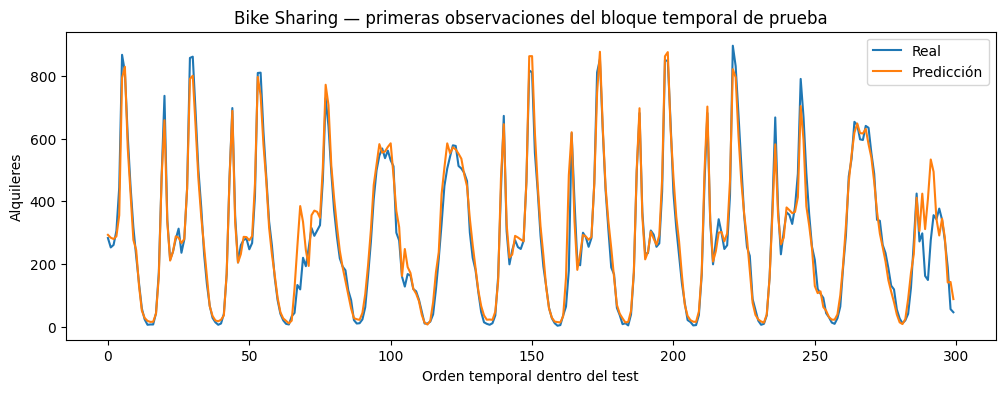

In [35]:
# Ordenamos cronológicamente y reservamos el último 20 % como futuro.
# `casual` y `registered` se eliminan porque su suma define el target `cnt`.
# Usarlas permitiría reconstruir la respuesta y produciría leakage algebraico.

# 59. Time split + modelo de regresión
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Orden temporal: NO hacemos shuffle.
bike_fe = bike_fe.sort_values("timestamp").reset_index(drop=True)

# Eliminar columnas que provocan identificación/leakage o no son modelables directamente.
drop_cols = [
    "target_count", "timestamp", "date_parsed", "dteday", "date",
    "instant", "casual", "registered"
]
feature_cols_bike = [c for c in bike_fe.columns if c not in drop_cols]

# Para este mini-proyecto usamos únicamente columnas numéricas.
Xb = bike_fe[feature_cols_bike].select_dtypes(include=[np.number]).copy()
yb = bike_fe["target_count"].astype(float)

cut = int(len(bike_fe)*0.80)
Xb_train, Xb_test = Xb.iloc[:cut], Xb.iloc[cut:]
yb_train, yb_test = yb.iloc[:cut], yb.iloc[cut:]

bike_model = HistGradientBoostingRegressor(
    learning_rate=0.07,
    max_iter=300,
    random_state=42
)
bike_model.fit(Xb_train, yb_train)
pred = bike_model.predict(Xb_test)

bike_metrics = {
    "MAE": mean_absolute_error(yb_test, pred),
    "RMSE": mean_squared_error(yb_test, pred) ** 0.5,
    "R2": r2_score(yb_test, pred),
}

display(pd.Series(bike_metrics))

fig, ax = plt.subplots(figsize=(12,4))
n_show = min(300, len(yb_test))
ax.plot(np.arange(n_show), yb_test.iloc[:n_show].to_numpy(), label="Real")
ax.plot(np.arange(n_show), pred[:n_show], label="Predicción")
ax.set_title("Bike Sharing — primeras observaciones del bloque temporal de prueba")
ax.set_xlabel("Orden temporal dentro del test")
ax.set_ylabel("Alquileres")
ax.legend()
plt.show()

# 60. ¿Por qué un split temporal?

En datos cronológicos:

```text
PASADO                              FUTURO
|----------------------------------|---------|
              TRAIN                    TEST
```

Un split aleatorio permitiría que observaciones “futuras” ayuden a entrenar un modelo evaluado sobre observaciones “pasadas”. Aunque no siempre sea leakage directo, puede producir una evaluación demasiado optimista cuando existen tendencia, estacionalidad o cambios de régimen.

### Diferencia entre split aleatorio y temporal

Un split aleatorio pregunta aproximadamente: “¿generaliza a observaciones intercambiables de la misma distribución?”.  
Un split temporal pregunta: “¿puede aprender del pasado y funcionar en un periodo posterior?”.

Para demanda, precios, macroeconomía o sensores, la segunda pregunta suele parecerse más al despliegue real.

# 61. Fuente real C — World Bank Indicators API v2

La API del Banco Mundial permite construir URLs parametrizadas.

Ejemplo conceptual:

```text
https://api.worldbank.org/v2/
    country/BOL;PER;COL;ECU/
    indicator/NY.GDP.PCAP.CD
    ?date=2000:2025
    &format=json
```

Trabajaremos con:

- `NY.GDP.PCAP.CD` — PIB per cápita, US$ corrientes.
- `FP.CPI.TOTL.ZG` — inflación de precios al consumidor, % anual.
- `SL.UEM.TOTL.ZS` — desempleo total, % de la fuerza laboral.
- `SP.POP.TOTL` — población total.

La utilidad didáctica es distinta: aquí no descargamos un archivo fijo; **construimos una consulta a una API**.

### Qué enseñamos con una API

Una API introduce conceptos adicionales:

- **endpoint:** ruta que ofrece un recurso;
- **parámetro:** parte de la consulta que controla país, indicador o rango;
- **JSON:** formato estructurado de respuesta;
- **status code:** resultado HTTP de la solicitud;
- **timeout:** límite para evitar una espera indefinida;
- **snapshot:** copia local de la respuesta transformada.

El valor pedagógico es aprender a construir una cadena de datos que comienza fuera del notebook.

In [38]:
# Los códigos ISO3 identifican países y los códigos del Banco Mundial identifican series.
# `fetch_world_bank_panel` consulta cada indicador, conserva la versión larga
# y crea una tabla ancha de una fila por país-año.

# 62. Descargar panel Bolivia–Perú–Colombia–Ecuador desde World Bank API
COUNTRIES = ["BOL", "PER", "COL", "ECU"]

WB_INDICATORS = {
    "gdp_pc_usd": "NY.GDP.PCAP.CD",
    "inflation_pct": "FP.CPI.TOTL.ZG",
    "unemployment_pct": "SL.UEM.TOTL.ZS",
    "population": "SP.POP.TOTL",
}

wb_panel, wb_long, wb_urls = fetch_world_bank_panel(
    countries=COUNTRIES,
    indicators=WB_INDICATORS,
    start_year=2000,
    end_year=2025,
)

print("Panel:", wb_panel.shape)
display(wb_panel.tail(16))

print("\nURLs construidas:")
for name, url in wb_urls.items():
    print(name, "->", url)

Panel: (104, 7)


,country,countryiso3code,year,gdp_pc_usd,inflation_pct,population,unemployment_pct
88,Peru,PER,2010,5072.114940,1.528321,29086019.0,3.600
89,Peru,PER,2011,5861.357936,3.369311,29304086.0,3.477
90,Peru,PER,2012,6519.378530,3.611213,29550366.0,3.238
91,Peru,PER,2013,6746.800257,2.767897,29817919.0,3.575
92,Peru,PER,2014,6667.134104,3.411946,30115826.0,3.208
93,Peru,PER,2015,6231.711503,3.398092,30457600.0,3.272
94,Peru,PER,2016,6217.036000,3.557177,30866494.0,3.741
95,Peru,PER,2017,6736.166937,2.994900,31324637.0,3.691
96,Peru,PER,2018,6978.491215,1.509154,31897584.0,3.492
97,Peru,PER,2019,7037.008037,2.252122,32449303.0,3.379



URLs construidas:
gdp_pc_usd -> https://api.worldbank.org/v2/country/BOL;PER;COL;ECU/indicator/NY.GDP.PCAP.CD?date=2000:2025&format=json&per_page=20000
inflation_pct -> https://api.worldbank.org/v2/country/BOL;PER;COL;ECU/indicator/FP.CPI.TOTL.ZG?date=2000:2025&format=json&per_page=20000
unemployment_pct -> https://api.worldbank.org/v2/country/BOL;PER;COL;ECU/indicator/SL.UEM.TOTL.ZS?date=2000:2025&format=json&per_page=20000
population -> https://api.worldbank.org/v2/country/BOL;PER;COL;ECU/indicator/SP.POP.TOTL?date=2000:2025&format=json&per_page=20000


In [39]:
# Una API es una fuente viva: mañana podría devolver una revisión.
# Congelamos el panel consultado hoy y registramos todas las URLs exactas
# para poder atribuir cambios futuros a la fuente y no al código.

# 63. Congelar snapshot del API y registrar hashes
wb_raw_path = ROOT/"data/external_raw/world_bank_panel_2000_2025.csv"
wb_panel.to_csv(wb_raw_path, index=False)

wb_manifest = save_source_manifest(
    ROOT/"artifacts/external/world_bank_manifest.json",
    source_name="World Bank Indicators API v2",
    source_url="https://api.worldbank.org/v2/",
    local_file=wb_raw_path,
    extra={
        "countries": COUNTRIES,
        "indicators": WB_INDICATORS,
        "query_urls": wb_urls,
        "note": "Snapshot local: protege el análisis frente a revisiones futuras del API."
    }
)
wb_manifest

{'source_name': 'World Bank Indicators API v2',
 'source_url': 'https://api.worldbank.org/v2/',
 'retrieved_utc': '2026-10-12T02:45:58.070255+00:00',
 'local_file': '/content/drive/MyDrive/GEM_EDUCA/gem_s03/data/external_raw/world_bank_panel_2000_2025.csv',
 'sha256': '39f1897e02ad54573459faf355983e26ad016569b8a296618774a2ea2b06907c',
 'bytes': 7080,
 'countries': ['BOL', 'PER', 'COL', 'ECU'],
 'indicators': {'gdp_pc_usd': 'NY.GDP.PCAP.CD',
  'inflation_pct': 'FP.CPI.TOTL.ZG',
  'unemployment_pct': 'SL.UEM.TOTL.ZS',
  'population': 'SP.POP.TOTL'},
 'query_urls': {'gdp_pc_usd': 'https://api.worldbank.org/v2/country/BOL;PER;COL;ECU/indicator/NY.GDP.PCAP.CD?date=2000:2025&format=json&per_page=20000',
  'inflation_pct': 'https://api.worldbank.org/v2/country/BOL;PER;COL;ECU/indicator/FP.CPI.TOTL.ZG?date=2000:2025&format=json&per_page=20000',
  'unemployment_pct': 'https://api.worldbank.org/v2/country/BOL;PER;COL;ECU/indicator/SL.UEM.TOTL.ZS?date=2000:2025&format=json&per_page=20000',
  'pop

# 64. Feature engineering para panel país‑año

Para cada país construiremos:

$$
g_{t}^{GDPpc} = 100\left(\frac{GDPpc_t}{GDPpc_{t-1}}-1\right)
$$

y rezagos:

$$
x_{t-1}=L_1(x_t)
$$

Los rezagos son fundamentales cuando queremos que una observación de $t$ use información disponible hasta $t-1$.

### Panel y rezagos

Un **panel** combina dimensión transversal (país) y temporal (año). El rezago debe calcularse **dentro de cada país**, no sobre toda la tabla.

Por eso usamos `groupby("countryiso3code")` antes de `shift(1)`.

El crecimiento del PIB per cápita se calcula como:

$$g_{it}^{GDPpc}=100\left(\frac{GDPpc_{it}}{GDPpc_{i,t-1}}-1\right)$$

y un rezago de primer orden como:

$$x_{i,t-1}=L_1(x_{it})$$

La primera observación de cada país queda sin rezago porque no existe un periodo anterior dentro de la muestra.

In [40]:
# Ordenamos dentro de país antes de cualquier operación temporal.
# `groupby` garantiza que `shift(1)` de Bolivia nunca tome el último dato de Perú.
# `pct_change(fill_method=None)` evita rellenar faltantes implícitamente.

# 65. Features de panel: crecimiento, logs y lags
wb = wb_panel.sort_values(["countryiso3code","year"]).copy()
g = wb.groupby("countryiso3code", group_keys=False)

# Tasa interanual dentro de cada país: compara t con t-1 del mismo ISO3.
wb["gdp_pc_growth_pct"] = g["gdp_pc_usd"].pct_change(fill_method=None) * 100
wb["log_population"] = np.log(wb["population"].where(wb["population"] > 0))

# `shift(1)` genera información rezagada; el primer año de cada país queda NaN.
for col in ["gdp_pc_usd", "inflation_pct", "unemployment_pct"]:
    wb[f"{col}_lag1"] = g[col].shift(1)

wb["inflation_change"] = wb["inflation_pct"] - wb["inflation_pct_lag1"]
wb["unemployment_change"] = wb["unemployment_pct"] - wb["unemployment_pct_lag1"]

display(wb.tail(20))

,country,countryiso3code,year,gdp_pc_usd,inflation_pct,population,unemployment_pct,gdp_pc_growth_pct,log_population,gdp_pc_usd_lag1,inflation_pct_lag1,unemployment_pct_lag1,inflation_change,unemployment_change
84,Peru,PER,2006,3129.559965,2.002258,28324491.0,4.170,15.624017,17.159237,2706.669473,1.616302,4.870,0.385956,-0.700
85,Peru,PER,2007,3581.089308,1.779986,28530699.0,4.080,14.427886,17.166491,3129.559965,2.002258,4.170,-0.222272,-0.090
86,Peru,PER,2008,4197.584446,5.785876,28719041.0,4.030,17.215296,17.173071,3581.089308,1.779986,4.080,4.005890,-0.050
87,Peru,PER,2009,4181.187555,2.936232,28896811.0,3.960,-0.390627,17.179242,4197.584446,5.785876,4.030,-2.849644,-0.070
88,Peru,PER,2010,5072.114940,1.528321,29086019.0,3.600,21.307999,17.185768,4181.187555,2.936232,3.960,-1.407911,-0.360
89,Peru,PER,2011,5861.357936,3.369311,29304086.0,3.477,15.560432,17.193238,5072.114940,1.528321,3.600,1.840990,-0.123
90,Peru,PER,2012,6519.378530,3.611213,29550366.0,3.238,11.226419,17.201607,5861.357936,3.369311,3.477,0.241902,-0.239
91,Peru,PER,2013,6746.800257,2.767897,29817919.0,3.575,3.488396,17.210620,6519.378530,3.611213,3.238,-0.843316,0.337
92,Peru,PER,2014,6667.134104,3.411946,30115826.0,3.208,-1.180799,17.220561,6746.800257,2.767897,3.575,0.644049,-0.367
93,Peru,PER,2015,6231.711503,3.398092,30457600.0,3.272,-6.530881,17.231846,6667.134104,3.411946,3.208,-0.013854,0.064


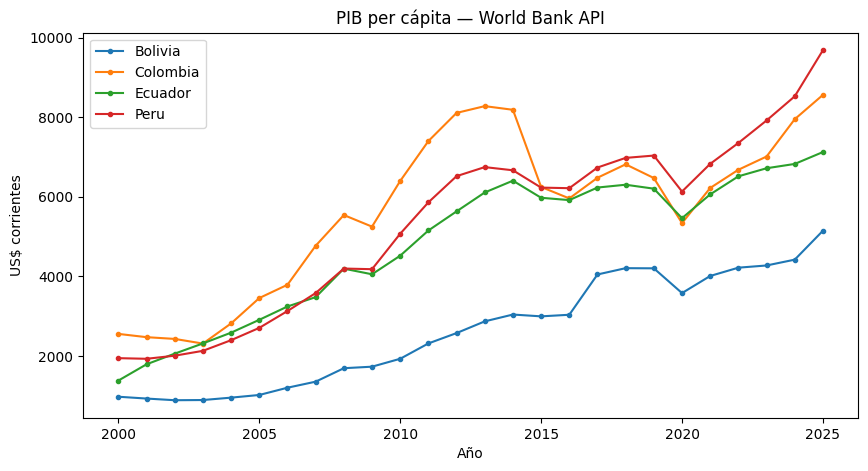

In [41]:
# Graficamos cada país como serie independiente para comprobar tendencia,
# cobertura temporal y valores faltantes antes de usar el panel en modelos.

# 66. Visualizar una feature real del Banco Mundial
fig, ax = plt.subplots(figsize=(10,5))
for country, d in wb.groupby("country"):
    ax.plot(d["year"], d["gdp_pc_usd"], marker="o", markersize=3, label=country)

ax.set_title("PIB per cápita — World Bank API")
ax.set_xlabel("Año")
ax.set_ylabel("US$ corrientes")
ax.legend()
plt.show()

# 67. Árbol de reproducibilidad para APIs vivas

```text
API
│
├── ¿La URL está registrada?
│   └── sí
├── ¿La fecha de descarga está registrada?
│   └── sí
├── ¿Guardamos RAW?
│   └── sí
├── ¿Calculamos SHA-256?
│   └── sí
├── ¿La transformación está en código?
│   └── sí
└── ¿Podemos distinguir revisión de error?
    ├── mismo URL + hash distinto → revisar actualización de fuente
    └── mismo RAW + resultado distinto → revisar código/entorno
```

Esta diferencia es importante: **reproducir una descarga viva** y **reproducir un análisis histórico** no son exactamente el mismo problema.

### Diagnóstico de diferencias futuras

Si ejecutamos el notebook dentro de seis meses y cambia el hash del snapshot descargado:

- **misma URL + hash diferente:** probablemente cambió la fuente o fue revisada;
- **mismo RAW + resultado diferente:** revisar código, versiones o aleatoriedad;
- **mismo RAW + mismo código + mismo entorno + resultado diferente:** investigar operaciones no deterministas.

Esta lógica es la base de la trazabilidad de datos.

# 68. Mini-proyecto integrador de clase

El alumnado puede escoger una de tres rutas:

```text
RUTA A — BANK MARKETING
├── objetivo: clasificación
├── crear features
├── comparar con/sin duration
├── ROC-AUC y PR-AUC
└── justificar momento real de predicción

RUTA B — BIKE SHARING
├── objetivo: regresión
├── features cíclicas
├── eliminar leakage casual/registered
├── split temporal
└── MAE, RMSE y R²

RUTA C — WORLD BANK
├── objetivo: panel macro
├── descargar por API
├── construir lags y tasas de crecimiento
├── congelar snapshot + SHA-256
└── comparar países/años
```

### Entregable

Se debe entregar:

1. fuente y URL;
2. diccionario de variables;
3. árbol de decisiones de features;
4. lista explícita de posibles leakages;
5. código reproducible;
6. hash del RAW;
7. una tabla de resultados;
8. una conclusión que distinga **predicción**, **descripción** y **causalidad**.

# 69. Comprobación final de artefactos externos

Al terminar deberían existir archivos como:

```text
data/external_raw/
├── uci_bank_marketing.csv
├── uci_bike_sharing.csv
└── world_bank_panel_2000_2025.csv

artifacts/external/
├── uci_bank_marketing_manifest.json
├── uci_bike_sharing_manifest.json
└── world_bank_manifest.json
```

Cada manifiesto registra el origen y el SHA-256 del snapshot descargado.

In [42]:
# Esta celda funciona como auditoría final: muestra los snapshots de datos
# y los manifiestos que documentan su procedencia, tamaño y hash.

# 70. Listar lo generado por los laboratorios reales
for folder in [ROOT/"data/external_raw", ROOT/"artifacts/external"]:
    print("\n", folder)
    if folder.exists():
        for p in sorted(folder.glob("*")):
            print(" -", p.name, f"({p.stat().st_size:,} bytes)")


 /content/drive/MyDrive/GEM_EDUCA/gem_s03/data/external_raw
 - uci_bank_marketing.csv (3,290,739 bytes)
 - uci_bike_sharing.csv (944,762 bytes)
 - world_bank_panel_2000_2025.csv (7,080 bytes)

 /content/drive/MyDrive/GEM_EDUCA/gem_s03/artifacts/external
 - uci_bank_marketing_manifest.json (446 bytes)
 - uci_bike_sharing_manifest.json (447 bytes)
 - world_bank_manifest.json (1,277 bytes)



# 71. Checklist mental para cualquier proyecto de datos

Antes de aceptar un resultado, intenta responder sin mirar el código:

```text
DATOS
├── ¿Qué representa una fila?
├── ¿Cuál es la PK?
├── ¿Qué tablas se relacionan mediante FK?
├── ¿Qué datos faltan y por qué?
└── ¿Cuál es la fecha de corte?

FEATURES
├── ¿Cada feature existiría al predecir?
├── ¿Qué mecanismo intenta representar?
├── ¿Usa ventanas exclusivamente pasadas?
└── ¿Existe una versión más interpretable?

VALIDACIÓN
├── ¿El split imita producción?
├── ¿Hay entidades repetidas entre train y test?
├── ¿La métrica corresponde al costo real?
└── ¿El test permaneció realmente fuera del ajuste?

REPRODUCIBILIDAD
├── ¿Tengo RAW?
├── ¿Tengo URL / DOI / dataset ID?
├── ¿Tengo hash?
├── ¿Tengo configuración?
├── ¿Tengo versiones?
└── ¿Puedo recargar exactamente el pipeline?
```

La idea central de toda la sesión es esta:

**una buena feature no es solo una columna predictiva; es una representación con significado, disponible en el momento correcto y construida de manera reproducible.**
